# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions, plot_date_range
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor, HoeffdingAdaptiveTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/second_batch/commercial'

## Evaluation Settings

In [4]:
DATA_FREQUENCY = 'H'  # Hour frequency
FORECAST_HORIZON = '1h'
SPIKE_PROMINENCE = 2.0  # For commercial data

In [5]:
# Measure loading time
start_time = time.time()

# Load data
train, valid, test = load_dataset(data_dir=data_dir, prefix='sb_com_hour_wfv', use_numpy=True)
FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
           'consumption_lag_1h', 'consumption_lag_2h', 'consumption_lag_3h', 'consumption_lag_24h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 2 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 2 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.00 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
train[0][0]

array([[Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub1', 22.0, ..., 0.625, 0.6275000000000546, 0.621818181818195],
       [Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub3', 22.0, ..., 0.31666666666660603, 0.32416666666669397,
        0.3072727272727372],
       [Timestamp('2024-06-07 00:00:00+0200', tz='Europe/Prague'),
        'sub2', 22.0, ..., 0.004166666666662877, 0.0033333333333303017,
        0.003636363636370664],
       ...,
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub2', 21.0, ..., 0.004166666666662877, 0.004166666666662877,
        0.0033333333333397754],
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub1', 21.0, ..., 0.5883333333334425, 0.6208333333330908,
        0.6091666666667758],
       [Timestamp('2024-07-04 23:00:00+0200', tz='Europe/Prague'),
        'sub3', 21.0, ..., 0.3674999999999879, 0.37333333333344854,
        0.3758333333333515]], shape=(2016, 9

In [7]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 2 splits
Validation data: 2 splits
First train split shape: X=(2016, 9), y=(2016,)
First valid split shape: X=(2016, 9), y=(2016,)

Memory usage:
Train: 0.46 MB
Valid: 0.21 MB
Test: 0.09 MB
Total: 0.77 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (predict previous value)

In [8]:
update_freq = "1H"
baseline = PreviousValueRegressor
baseline_params = {}

In [9]:
baseline_train_period_predictions, baseline_valid_period_predictions,\
baseline_train_period_metrics, baseline_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=baseline,
    model_params=baseline_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0601
	MAE: 0.0335
	MAPE: 258.9494%

Directional Metrics:
	Directional Accuracy: 42.1759%
	First-Diff Correlation: 0.1024

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 0.9925
		F1: 0.9962
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0556
	MAE: 0.0292
	MAPE: 228.5929%

Directional Metrics:
	Directional Accuracy: 40.1575%
	First-Diff Correlation: 0.1059

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

#### Results

In [10]:
print("\n\nValid period metrics:")
baseline_all_time_valid_metrics = all_time_aggregation_metrics(baseline_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0578 ± 0.0023
	MAE: 0.0313 ± 0.0022
	MAPE: 243.7712% ± 15.1782%

	Directional Metrics:
		Directional Accuracy: 41.1667% ± 1.0092%
		First-Diff Correlation: 0.1042 ± 0.0018

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 1.0000 ± 0.0000
		Spike Recall: 1.0000 ± 0.0000
		Spike F1: 1.0000 ± 0.0000
		Drop Precision: 1.0000 ± 0.0000
		Drop Recall: 0.9962 ± 0.0038
		Drop F1: 0.9981 ± 0.0019
Daily Metrics:
	RMSE: 0.0778 ± 0.0110
	MAE: 0.0468 ± 0.0070
	MAPE: 3.5903% ± 0.5330%

	Directional Metrics:
		Directional Accuracy: 98.1481% ± 1.8519%
		First-Diff Correlation: 0.9631 ± 0.0148

	Immediate Detection (delta=0):
		Spi

#### Validation plots

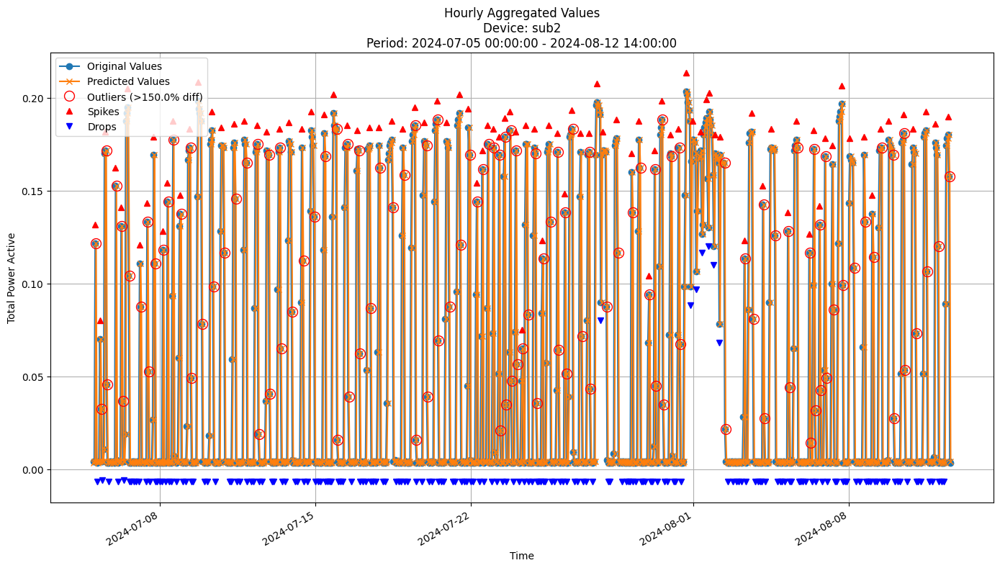


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0589
MAE: 0.0323
MAPE: 250.5989%

Directional Metrics:
Directional Accuracy: 41.5767%
First-Diff Correlation: 0.1033

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 0.9947
  F1 Score: 0.9973


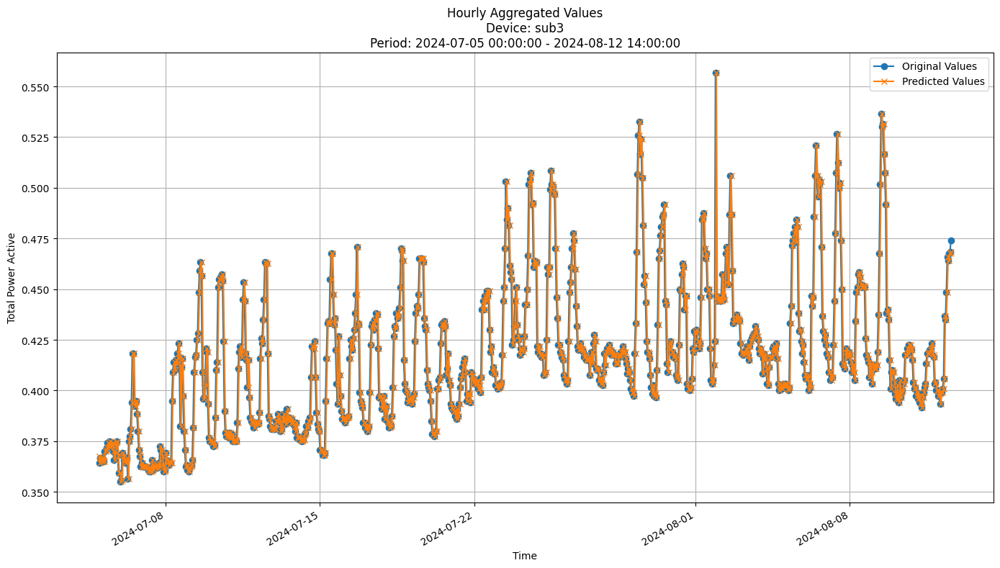


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0128
MAE: 0.0072
MAPE: 1.6742%

Directional Metrics:
Directional Accuracy: 51.0799%
First-Diff Correlation: 0.2412

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


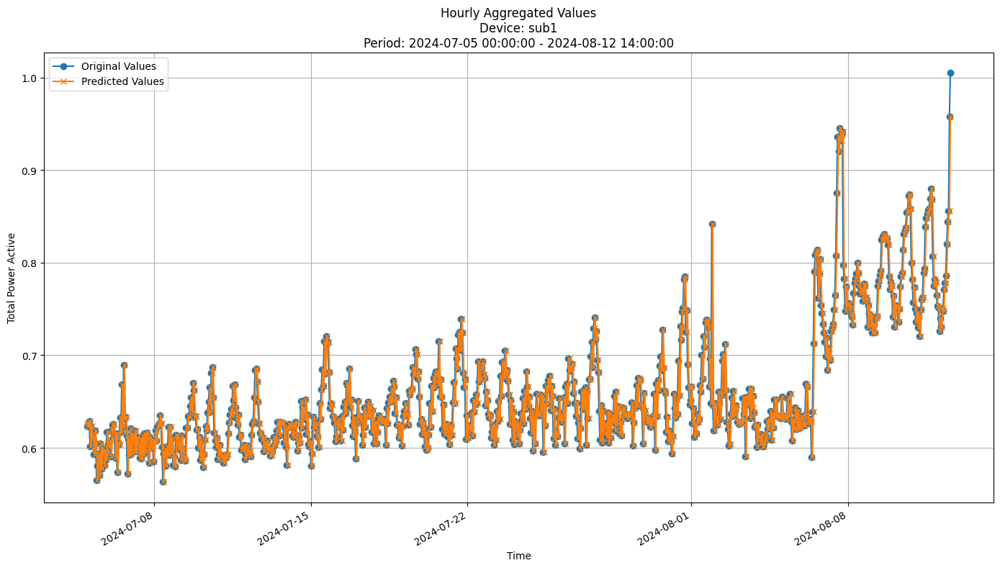


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0250
MAE: 0.0181
MAPE: 2.7465%

Directional Metrics:
Directional Accuracy: 37.0410%
First-Diff Correlation: -0.1352

Immediate Detection (delta=0):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [11]:
join_periods = [-1, -2]
# Device iteration
for device_id in baseline_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, baseline_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, baseline_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [12]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor
gbdt_params = {
    'n_estimators': 100,
    'learning_rate': 0.03,
    'subsample': 0.8,
    'max_depth': 10,
    'random_state': 42
}

In [13]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt,
    model_params=gbdt_params,
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00

Time: 0.18 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.23 seconds
Predicting for chunk from 2024-07-19 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0661
	MAE: 0.0479
	MAPE: 478.0913%

Directional Metrics:
	Directional Accuracy: 50.3726%
	First-Diff Correlation: 0.2214

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1067
		Recall: 0.1111
		F1: 0.1088
	Drops:
		Precision: 0.2297
		Recall: 0.1278
		F1: 0.1643

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00

Time: 0.26 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1096
	MAE: 0.0971
	MAPE: 2083.4295%

Directional Metrics:
	Directional Accuracy: 46.4567%
	First-Diff Correlation: -0.0337

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0882
		Recall: 0.1250
		F1: 0.1034
	Drops:
		Precision: 0.2121
		Recall: 0.1321
		F1: 0.1628

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2941
		Recall: 0.4167
		F1: 0.3448
	Drops:
		Precision: 0.4545
		Recall: 0.2830
		F1: 0.3488
----------------------------------------------

#### Results

In [14]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0215 ± 0.0029
	MAE: 0.0138 ± 0.0022
	MAPE: 176.4306% ± 27.0033%

	Directional Metrics:
		Directional Accuracy: 65.2513% ± 0.2736%
		First-Diff Correlation: 0.9103 ± 0.0263

	Immediate Detection (delta=0):
		Spike Precision: 0.6050 ± 0.0076
		Spike Recall: 0.6691 ± 0.0386
		Spike F1: 0.6347 ± 0.0132
		Drop Precision: 0.3431 ± 0.0121
		Drop Recall: 0.1853 ± 0.0132
		Drop F1: 0.2406 ± 0.0141

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8203 ± 0.0670
		Spike Recall: 0.9027 ± 0.0104
		Spike F1: 0.8585 ± 0.0415
		Drop Precision: 0.7698 ± 0.0330
		Drop Recall: 0.4147 ± 0.0029
		Drop F1: 0.5388 ± 0.0105
Daily Metrics:
	RMSE: 0.1118 ± 0.0071
	MAE: 0.0898 ± 0.0041
	MAPE: 9.9887% ± 0.2601%

	Directional Metrics:
		Directional Accuracy: 82.6263% ± 6.2626%
		First-Diff Correlation: 0.9177 ± 0.0009

	Immediate Detection (delta=0):
		Spi

#### Training plots

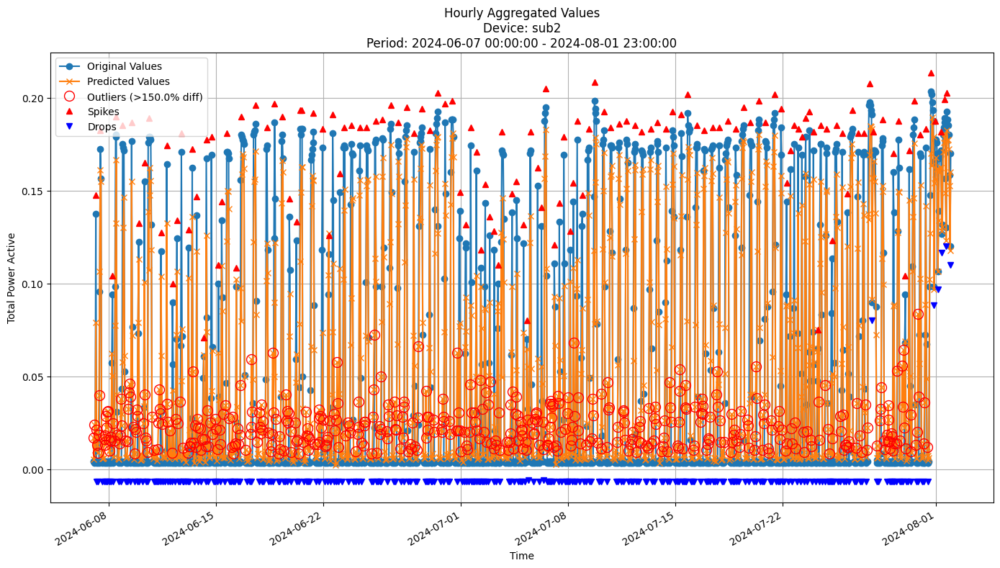


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0244
MAE: 0.0160
MAPE: 203.4338%

Directional Metrics:
Directional Accuracy: 65.5249%
First-Diff Correlation: 0.8840

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5000
  Recall: 0.0584
  F1 Score: 0.1046
Drops:
  Precision: 0.2500
  Recall: 0.0148
  F1 Score: 0.0279

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8750
  Recall: 0.1022
  F1 Score: 0.1830
Drops:
  Precision: 0.8125
  Recall: 0.0480
  F1 Score: 0.0906


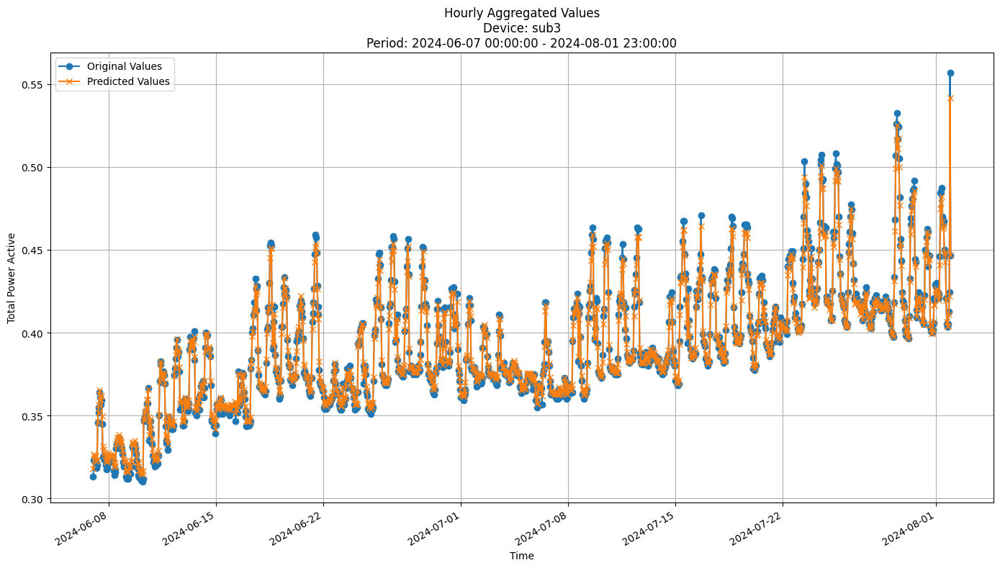


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0027
MAE: 0.0021
MAPE: 0.5371%

Directional Metrics:
Directional Accuracy: 85.6292%
First-Diff Correlation: 0.9873

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


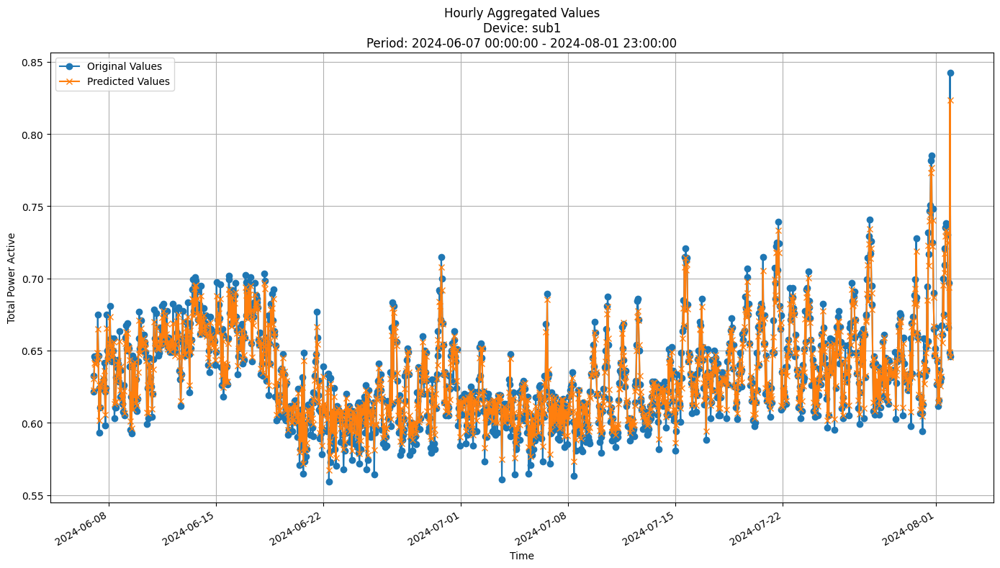


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0048
MAE: 0.0038
MAPE: 0.6099%

Directional Metrics:
Directional Accuracy: 92.8518%
First-Diff Correlation: 0.9830

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [15]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last few periods of predictions

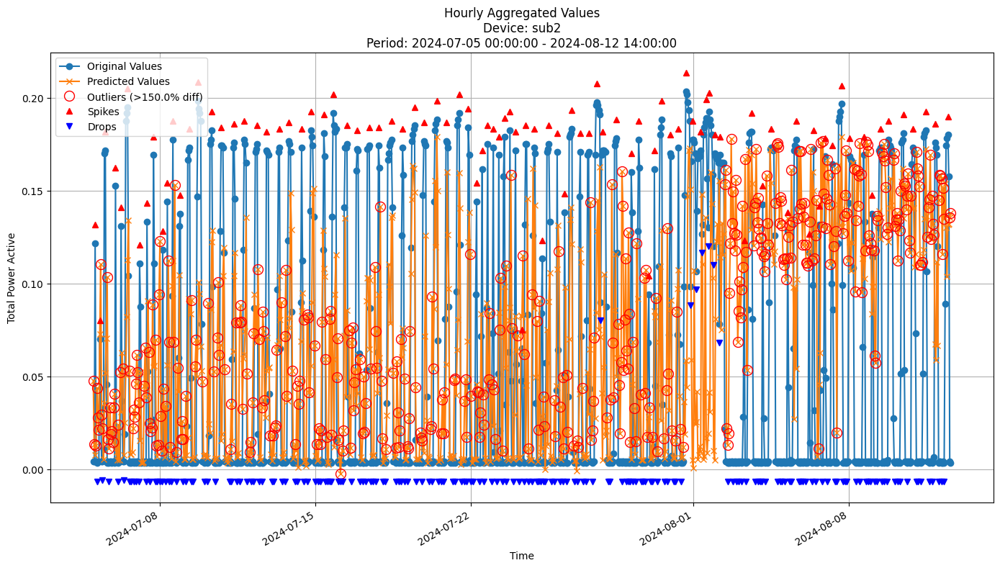


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0804
MAE: 0.0614
MAPE: 919.6892%

Directional Metrics:
Directional Accuracy: 49.2441%
First-Diff Correlation: 0.1667

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


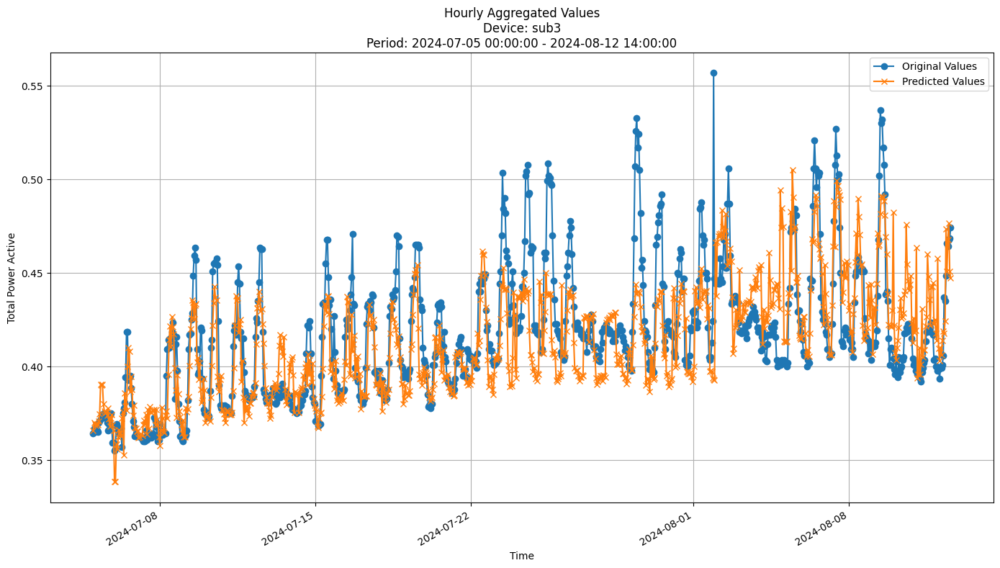


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0238
MAE: 0.0172
MAPE: 3.9881%

Directional Metrics:
Directional Accuracy: 53.7797%
First-Diff Correlation: 0.1440

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


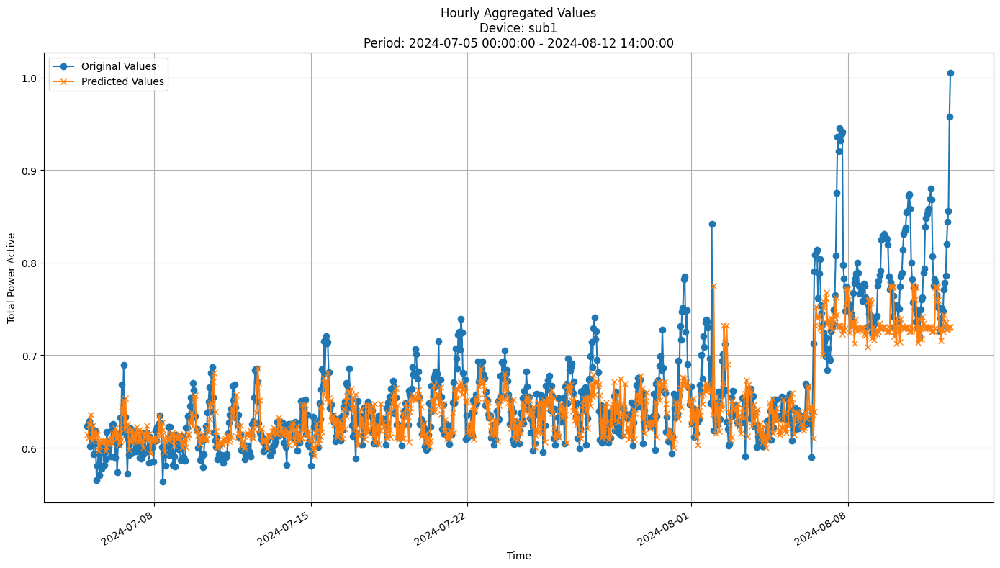


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0403
MAE: 0.0252
MAPE: 3.5744%

Directional Metrics:
Directional Accuracy: 53.2397%
First-Diff Correlation: 0.1272

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [16]:
join_periods = [-2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Random Forest model

In [17]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = {
    'n_estimators': 100,
    'max_depth': 10,
    'max_features': 'sqrt',
    'random_state': 42,
    'n_jobs': -1
}

In [18]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params,
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00

Time: 0.13 seconds
Predicting for chunk from 2024-07-05 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-07-19 00:00:00+02:00

Time: 0.11 seconds
Predicting for chunk from 2024-07-19 01:00:00+02:00 to 2024-08-01 23:00:00+02:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0640
	MAE: 0.0475
	MAPE: 444.6049%

Directional Metrics:
	Directional Accuracy: 52.1610%
	First-Diff Correlation: 0.3081

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1515
		Recall: 0.1389
		F1: 0.1449
	Drops:
		Precision: 0.2923
		Recall: 0.1429
		F1: 0.1919

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00

Time: 0.11 seconds
Predicting for chunk from 2024-08-02 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0828
	MAE: 0.0766
	MAPE: 1538.8069%

Directional Metrics:
	Directional Accuracy: 49.6063%
	First-Diff Correlation: 0.0913

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2222
		Recall: 0.1667
		F1: 0.1905
	Drops:
		Precision: 0.2632
		Recall: 0.0943
		F1: 0.1389

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3333
		Recall: 0.2500
		F1: 0.2857
	Drops:
		Precision: 0.5789
		Recall: 0.2075
		F1: 0.3056
-----------------------------------------------

#### Results

In [19]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0379 ± 0.0023
	MAE: 0.0274 ± 0.0022
	MAPE: 348.6134% ± 21.7504%

	Directional Metrics:
		Directional Accuracy: 61.8248% ± 0.4239%
		First-Diff Correlation: 0.7025 ± 0.0373

	Immediate Detection (delta=0):
		Spike Precision: 0.5014 ± 0.0542
		Spike Recall: 0.4685 ± 0.0700
		Spike F1: 0.4842 ± 0.0627
		Drop Precision: 0.3077 ± 0.0012
		Drop Recall: 0.1395 ± 0.0003
		Drop F1: 0.1919 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8310 ± 0.0261
		Spike Recall: 0.7741 ± 0.0567
		Spike F1: 0.8012 ± 0.0426
		Drop Precision: 0.8017 ± 0.0113
		Drop Recall: 0.3633 ± 0.0030
		Drop F1: 0.5000 ± 0.0051
Daily Metrics:
	RMSE: 0.1990 ± 0.0047
	MAE: 0.1574 ± 0.0019
	MAPE: 18.3771% ± 1.0308%

	Directional Metrics:
		Directional Accuracy: 63.2660% ± 4.0067%
		First-Diff Correlation: 0.6434 ± 0.0982

	Immediate Detection (delta=0):
		Sp

#### Training plots
Plot only the last period of predictions

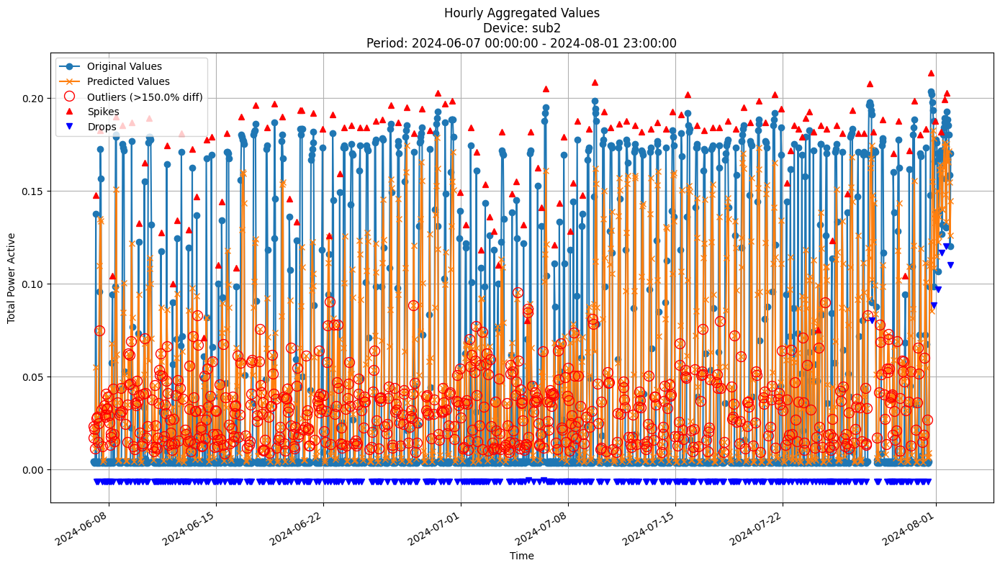


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0402
MAE: 0.0296
MAPE: 370.3639%

Directional Metrics:
Directional Accuracy: 62.2487%
First-Diff Correlation: 0.6652

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


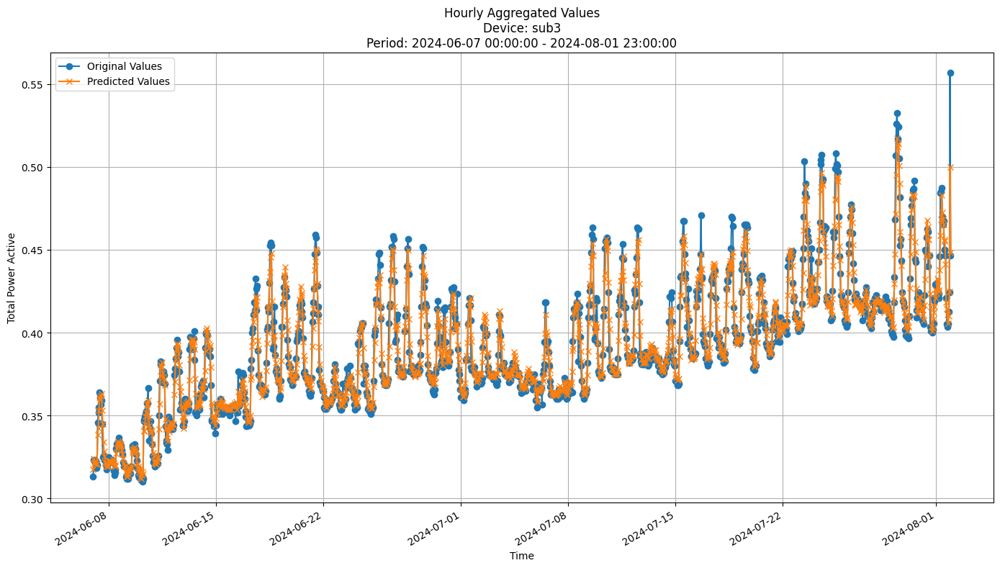


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0069
MAE: 0.0047
MAPE: 1.1725%

Directional Metrics:
Directional Accuracy: 71.2584%
First-Diff Correlation: 0.8181

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


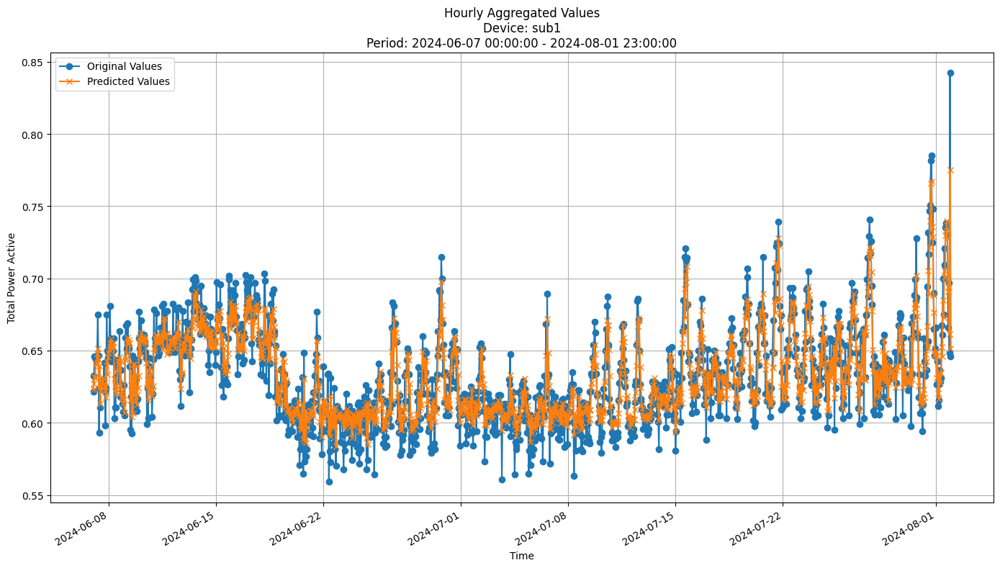


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0115
MAE: 0.0089
MAPE: 1.4103%

Directional Metrics:
Directional Accuracy: 81.0871%
First-Diff Correlation: 0.8561

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [20]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

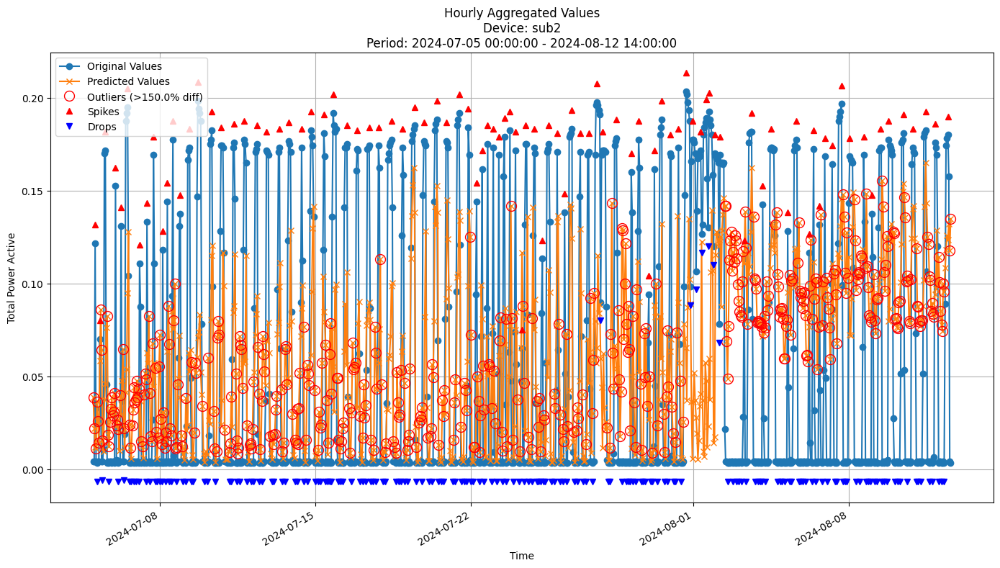


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0697
MAE: 0.0555
MAPE: 745.5990%

Directional Metrics:
Directional Accuracy: 51.4039%
First-Diff Correlation: 0.2660

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


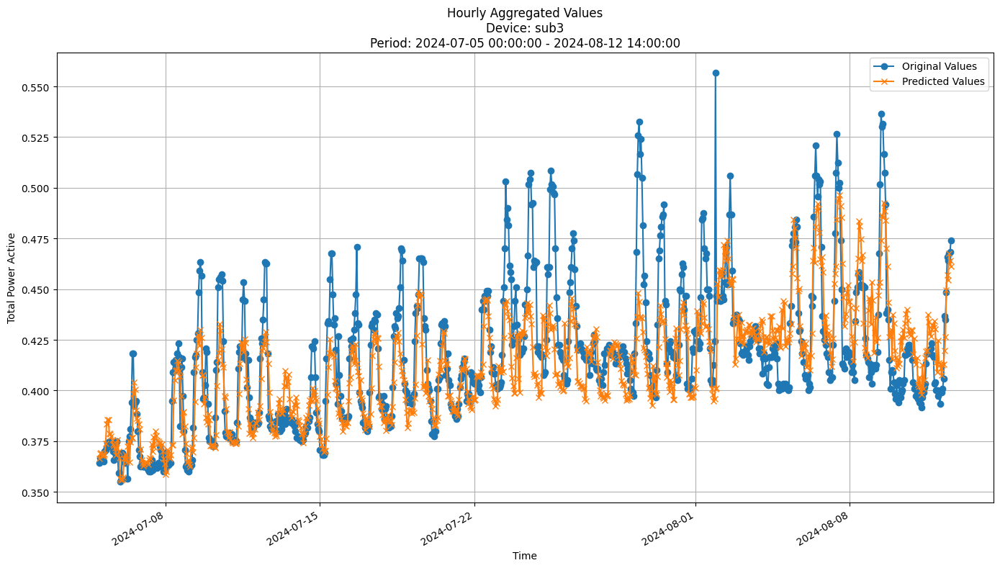


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0217
MAE: 0.0154
MAPE: 3.5305%

Directional Metrics:
Directional Accuracy: 56.8035%
First-Diff Correlation: 0.2091

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


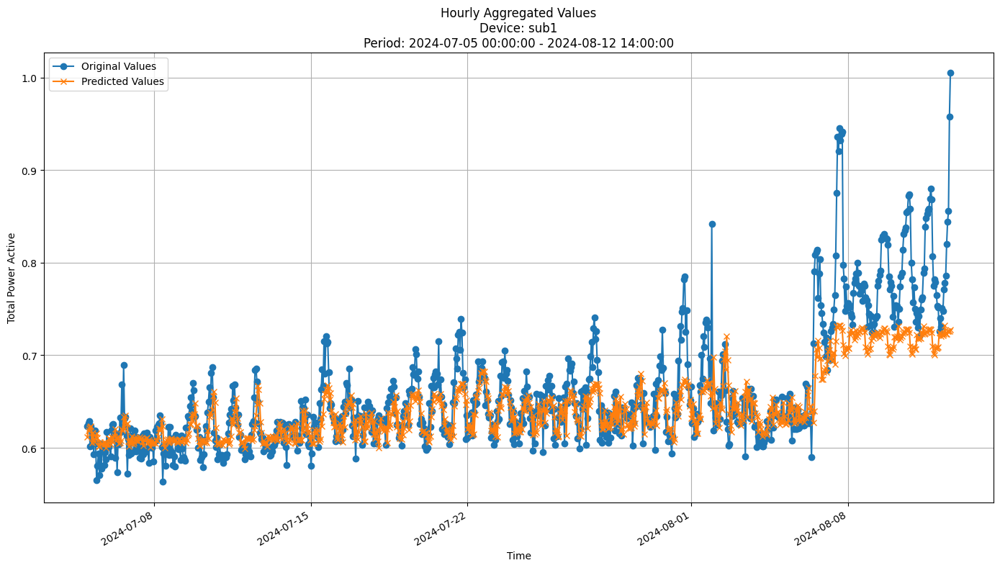


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0420
MAE: 0.0262
MAPE: 3.6722%

Directional Metrics:
Directional Accuracy: 53.9957%
First-Diff Correlation: 0.1777

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [21]:
join_periods = [-2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [22]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = {
    'grace_period': 10,
    'delta': 0.5,
    'max_depth': 10,
    'tau': 0.05,
    'leaf_prediction': 'mean'
}

In [23]:
hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params,
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0732
	MAE: 0.0573
	MAPE: 574.3176%

Directional Metrics:
	Directional Accuracy: 45.0075%
	First-Diff Correlation: 0.0583

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1404
		Recall: 0.1111
		F1: 0.1240
	Drops:
		Precision: 0.2982
		Recall: 0.1278
		F1: 0.1789

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4737
		Recall: 0.3750
		F1: 0.4186
	Drops:
		Precision: 0.7368
		Recall: 0.3158
		F1: 0.4421
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0748
	MAE: 0.0629
	MAPE: 784.5748%

Directional Metrics:
	Directional Accuracy: 44.4882%
	First-Diff Correlation: 0.0080

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0526
		Recall: 0.0417
		F1: 0.0465
	Drops:
		Precision: 0.3684
		Recall: 0.1321
		F1: 0.1944

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3684
		Recall: 0.2917
		F1: 0.3256
	Drops:
		Precision: 0.7368
		Recall: 0.2642
		F1: 0.3889
--------------------------------------------------
Dai

#### Results

In [24]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0659 ± 0.0016
	MAE: 0.0525 ± 0.0031
	MAPE: 726.0770% ± 22.5641%

	Directional Metrics:
		Directional Accuracy: 27.1508% ± 0.1761%
		First-Diff Correlation: 0.0742 ± 0.0000

	Immediate Detection (delta=0):
		Spike Precision: 0.1741 ± 0.0013
		Spike Recall: 0.1276 ± 0.0262
		Spike F1: 0.1459 ± 0.0180
		Drop Precision: 0.3168 ± 0.0536
		Drop Recall: 0.1101 ± 0.0002
		Drop F1: 0.1625 ± 0.0070

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5127 ± 0.0312
		Spike Recall: 0.3798 ± 0.0972
		Spike F1: 0.4322 ± 0.0760
		Drop Precision: 0.6871 ± 0.0906
		Drop Recall: 0.2404 ± 0.0096
		Drop F1: 0.3541 ± 0.0018
Daily Metrics:
	RMSE: 0.4377 ± 0.0947
	MAE: 0.3180 ± 0.0377
	MAPE: 37.3009% ± 0.6685%

	Directional Metrics:
		Directional Accuracy: 45.8923% ± 2.2559%
		First-Diff Correlation: 0.2049 ± 0.0960

	Immediate Detection (delta=0):
		Sp

#### Training plots
Plot only the last period of predictions

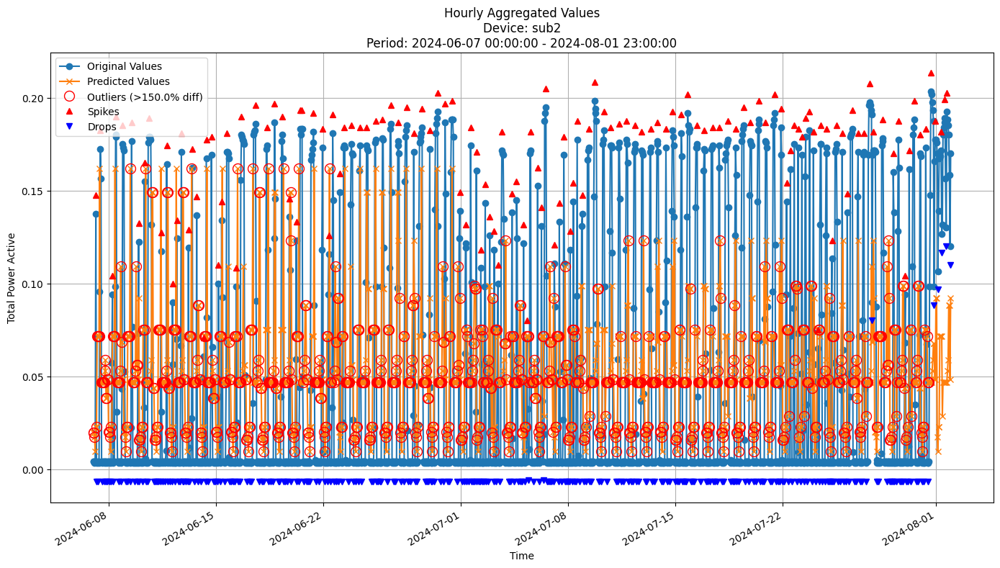


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0675
MAE: 0.0556
MAPE: 748.6411%

Directional Metrics:
Directional Accuracy: 27.3269%
First-Diff Correlation: 0.0743

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


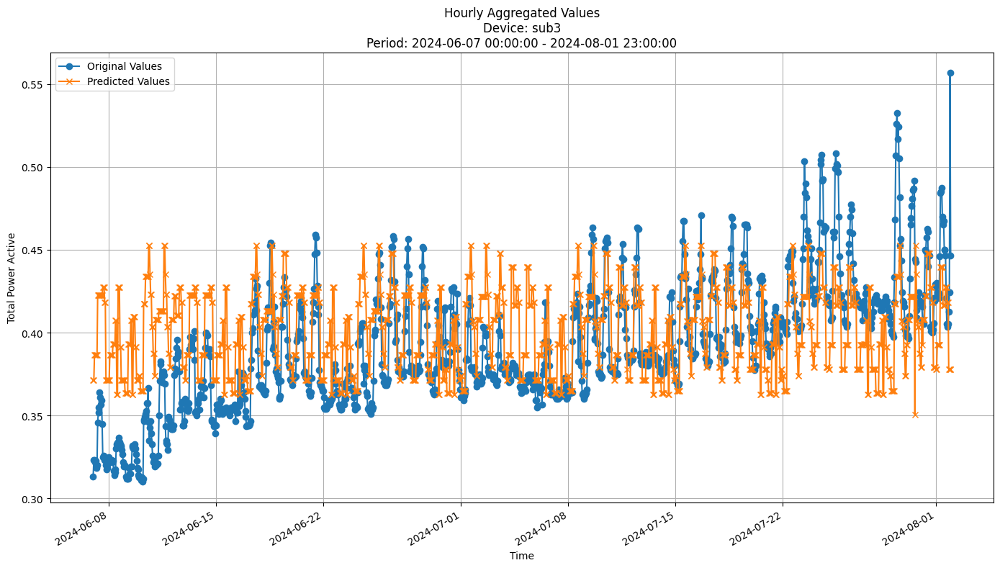


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0358
MAE: 0.0281
MAPE: 7.3598%

Directional Metrics:
Directional Accuracy: 22.7103%
First-Diff Correlation: 0.2046

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


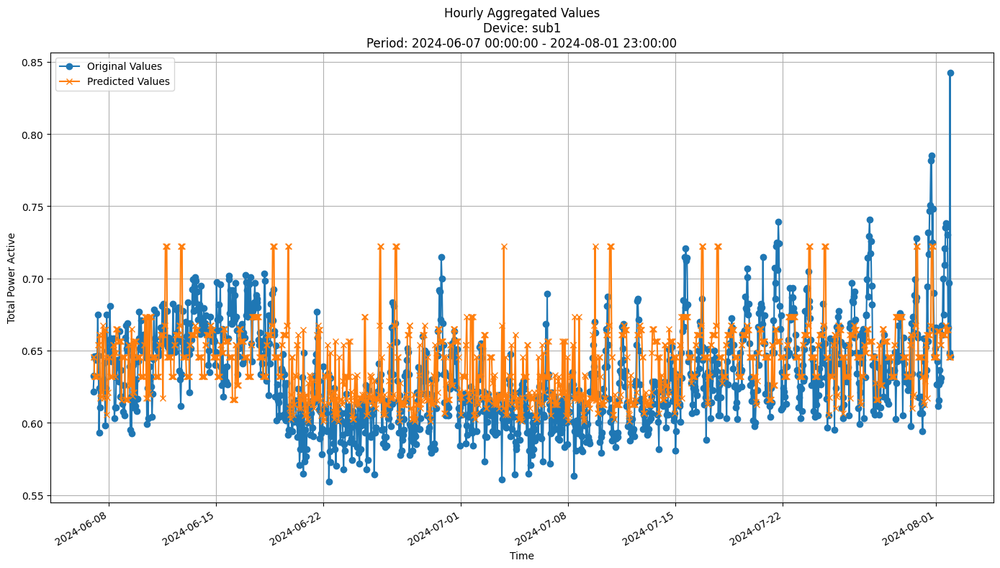


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0322
MAE: 0.0243
MAPE: 3.8542%

Directional Metrics:
Directional Accuracy: 25.4654%
First-Diff Correlation: 0.0131

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [25]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

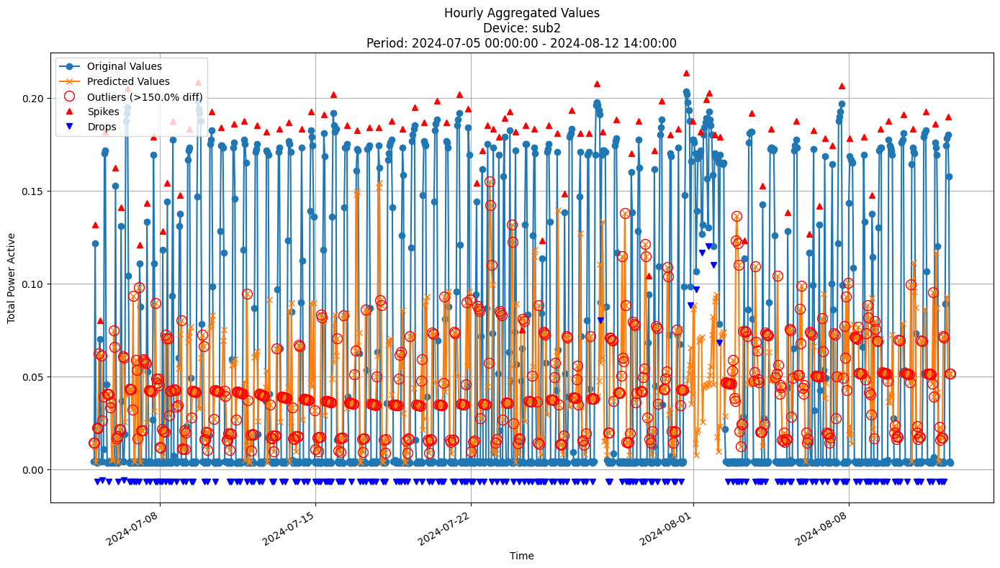


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0737
MAE: 0.0589
MAPE: 632.1553%

Directional Metrics:
Directional Accuracy: 44.8164%
First-Diff Correlation: 0.0460

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


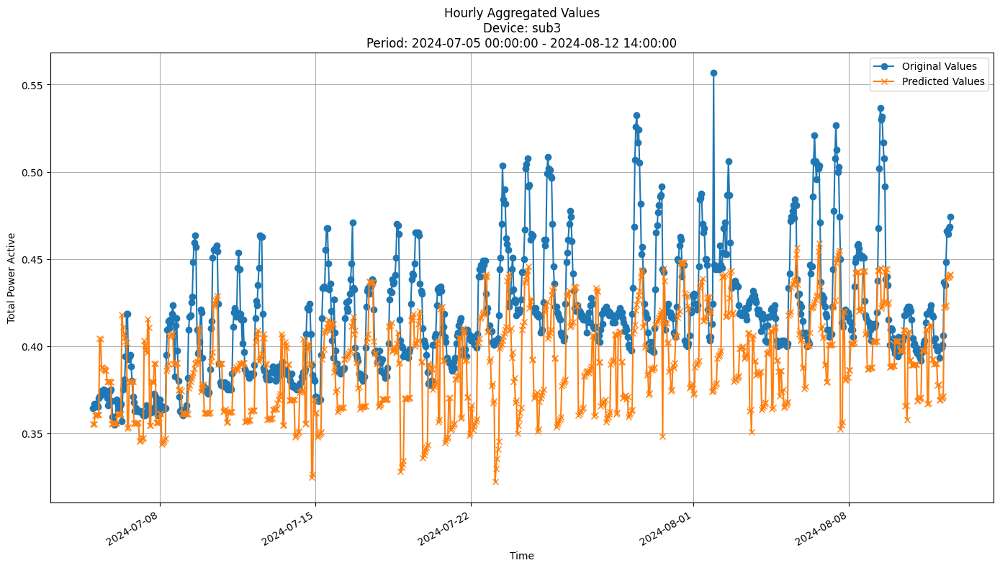


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0371
MAE: 0.0300
MAPE: 6.9873%

Directional Metrics:
Directional Accuracy: 49.8920%
First-Diff Correlation: 0.1930

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


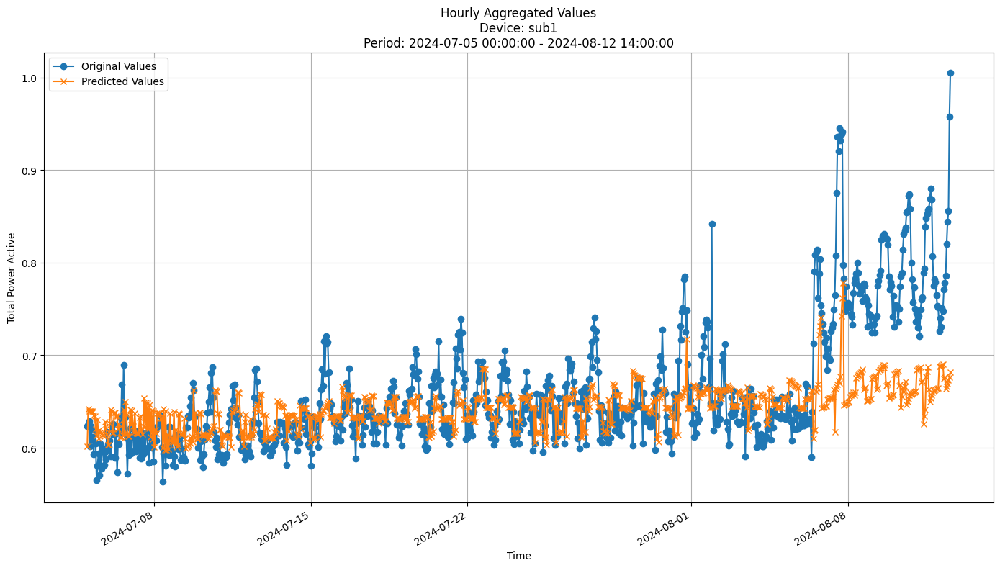


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0596
MAE: 0.0388
MAPE: 5.4516%

Directional Metrics:
Directional Accuracy: 46.5443%
First-Diff Correlation: 0.0265

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [26]:
join_periods = [-2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [27]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = {
    'n_models': 10,
    'max_features': 0.8,
    'aggregation_method': 'median',
    'grace_period': 10,
    'max_depth': 10,
    'delta': 0.5,  # split confidence
    'tau': 0.01,  # break ties
    'seed': 42
}

In [28]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0694
	MAE: 0.0538
	MAPE: 492.8273%

Directional Metrics:
	Directional Accuracy: 49.7765%
	First-Diff Correlation: 0.1479

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1698
		Recall: 0.1250
		F1: 0.1440
	Drops:
		Precision: 0.1731
		Recall: 0.0677
		F1: 0.0973

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5660
		Recall: 0.4167
		F1: 0.4800
	Drops:
		Precision: 0.5962
		Recall: 0.2331
		F1: 0.3351
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0712
	MAE: 0.0601
	MAPE: 734.5050%

Directional Metrics:
	Directional Accuracy: 45.2756%
	First-Diff Correlation: 0.0013

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0870
		Recall: 0.0833
		F1: 0.0851
	Drops:
		Precision: 0.1364
		Recall: 0.0566
		F1: 0.0800

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3043
		Recall: 0.2917
		F1: 0.2979
	Drops:
		Precision: 0.5000
		Recall: 0.2075
		F1: 0.2933
--------------------------------------------------
Dai

#### Results

In [29]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0601 ± 0.0023
	MAE: 0.0477 ± 0.0031
	MAPE: 612.4790% ± 32.4450%

	Directional Metrics:
		Directional Accuracy: 48.7894% ± 0.5032%
		First-Diff Correlation: 0.2180 ± 0.0122

	Immediate Detection (delta=0):
		Spike Precision: 0.1513 ± 0.0032
		Spike Recall: 0.1231 ± 0.0001
		Spike F1: 0.1358 ± 0.0013
		Drop Precision: 0.2679 ± 0.0564
		Drop Recall: 0.1064 ± 0.0255
		Drop F1: 0.1523 ± 0.0352

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5002 ± 0.0184
		Spike Recall: 0.4074 ± 0.0234
		Spike F1: 0.4490 ± 0.0216
		Drop Precision: 0.7290 ± 0.0367
		Drop Recall: 0.2880 ± 0.0233
		Drop F1: 0.4128 ± 0.0299
Daily Metrics:
	RMSE: 0.3717 ± 0.0982
	MAE: 0.2653 ± 0.0251
	MAPE: 28.6777% ± 0.2981%

	Directional Metrics:
		Directional Accuracy: 49.4949% ± 5.0505%
		First-Diff Correlation: 0.3754 ± 0.0987

	Immediate Detection (delta=0):
		Sp

#### Training plots

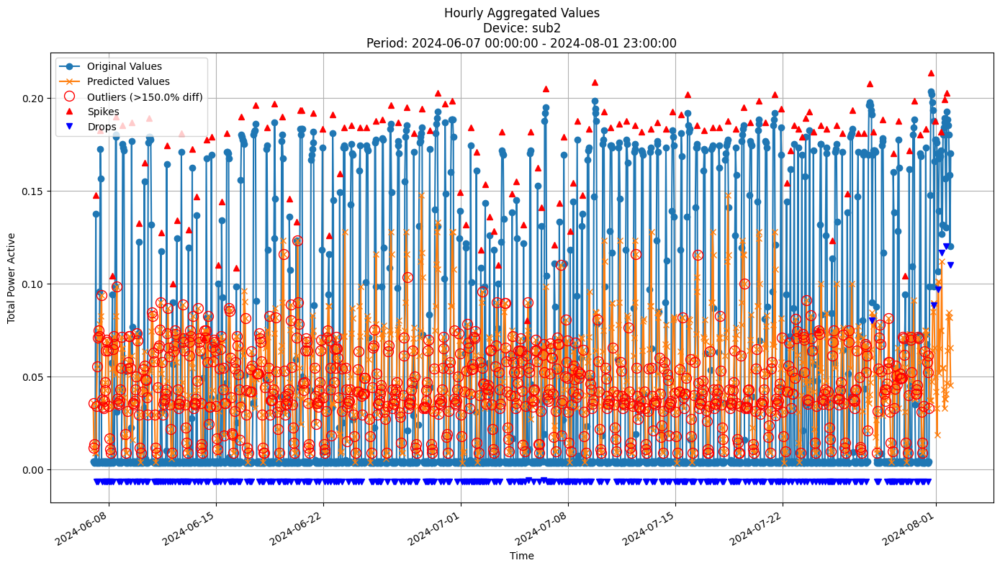


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0624
MAE: 0.0508
MAPE: 644.9240%

Directional Metrics:
Directional Accuracy: 49.2926%
First-Diff Correlation: 0.2057

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


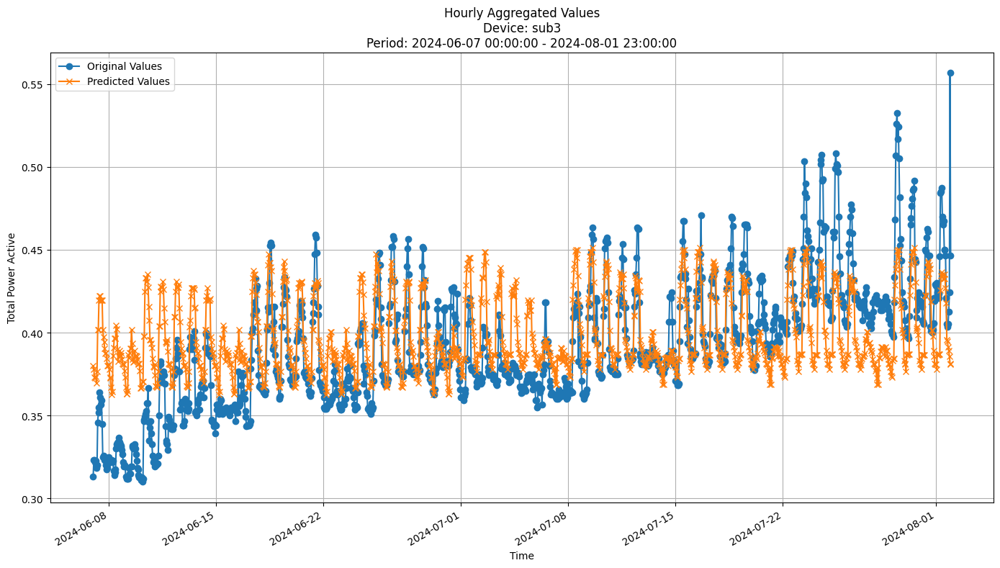


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0301
MAE: 0.0237
MAPE: 6.1876%

Directional Metrics:
Directional Accuracy: 51.0052%
First-Diff Correlation: 0.3931

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


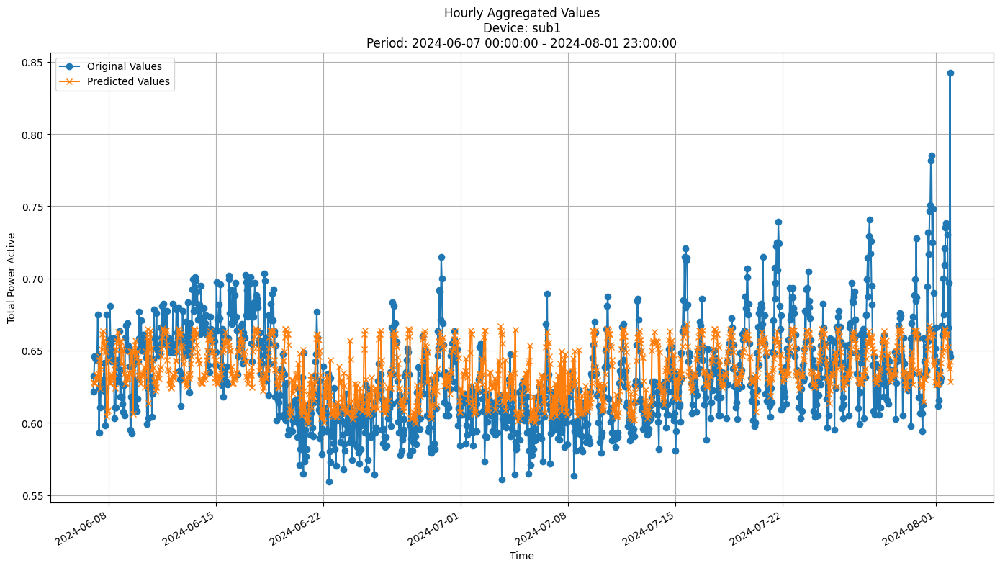


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0280
MAE: 0.0214
MAPE: 3.3663%

Directional Metrics:
Directional Accuracy: 52.1966%
First-Diff Correlation: 0.1467

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [30]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

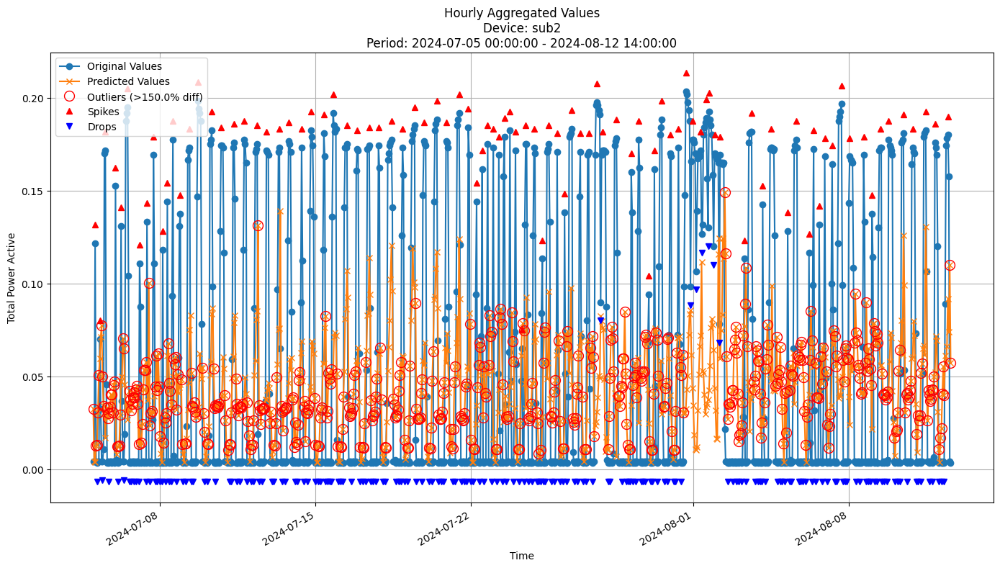


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0699
MAE: 0.0555
MAPE: 559.3082%

Directional Metrics:
Directional Accuracy: 48.5961%
First-Diff Correlation: 0.1069

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


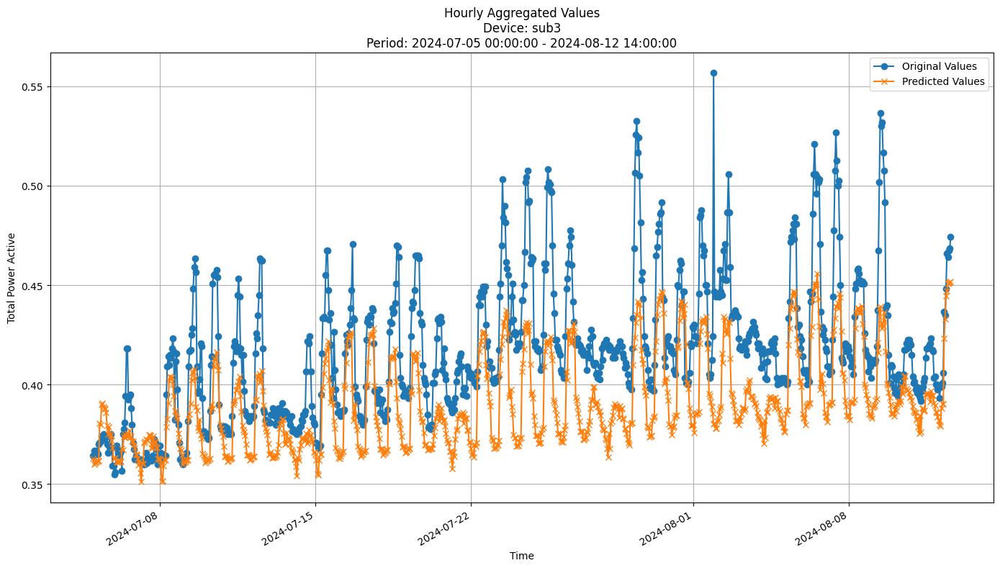


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0333
MAE: 0.0275
MAPE: 6.3563%

Directional Metrics:
Directional Accuracy: 58.8553%
First-Diff Correlation: 0.3830

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


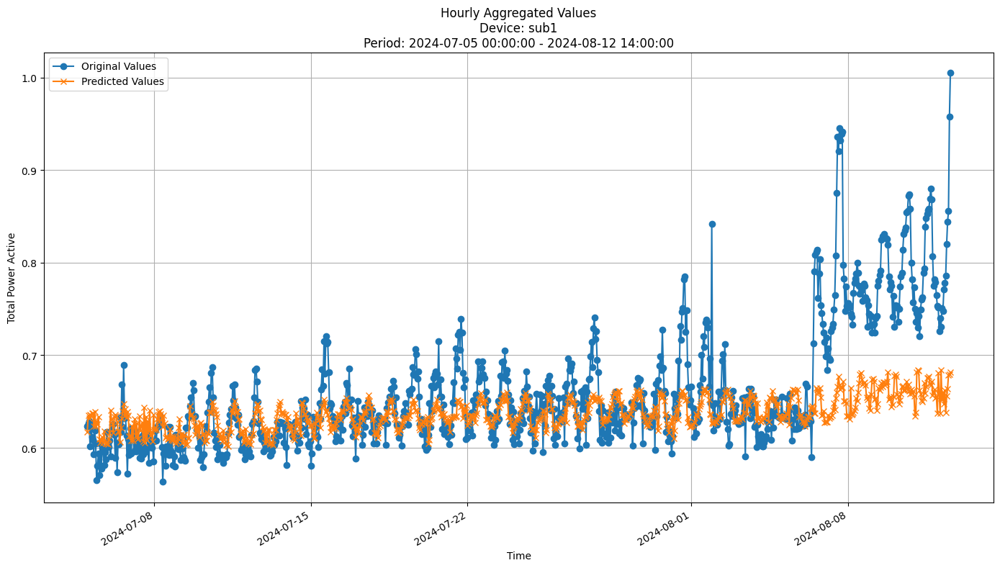


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0610
MAE: 0.0378
MAPE: 5.2232%

Directional Metrics:
Directional Accuracy: 52.6998%
First-Diff Correlation: 0.0692

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [31]:
join_periods = [-2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [32]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT
fodt_params = {
        "depth": 50,
        "grace_period": 0,
        "split_confidence": 0.005,
        "option": 'hf',
        "eagerness" : 1000,
        "grace_period_depth" : 0  # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes
}

In [33]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt,
    model_params=fodt_params,
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0755
	MAE: 0.0588
	MAPE: 498.5317%

Directional Metrics:
	Directional Accuracy: 42.1759%
	First-Diff Correlation: 0.0370

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1034
		Recall: 0.0417
		F1: 0.0594
	Drops:
		Precision: 0.2857
		Recall: 0.0602
		F1: 0.0994

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3448
		Recall: 0.1389
		F1: 0.1980
	Drops:
		Precision: 0.8571
		Recall: 0.1805
		F1: 0.2981
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0739
	MAE: 0.0583
	MAPE: 547.5164%

Directional Metrics:
	Directional Accuracy: 42.9134%
	First-Diff Correlation: -0.0176

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1818
		Recall: 0.0833
		F1: 0.1143
	Drops:
		Precision: 0.2727
		Recall: 0.0566
		F1: 0.0938

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4545
		Recall: 0.2083
		F1: 0.2857
	Drops:
		Precision: 0.7273
		Recall: 0.1509
		F1: 0.2500
--------------------------------------------------
Da

#### Results

In [34]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0647 ± 0.0031
	MAE: 0.0501 ± 0.0028
	MAPE: 550.5773% ± 4.2886%

	Directional Metrics:
		Directional Accuracy: 43.6859% ± 3.2984%
		First-Diff Correlation: 0.2086 ± 0.0195

	Immediate Detection (delta=0):
		Spike Precision: 0.2132 ± 0.0725
		Spike Recall: 0.0941 ± 0.0289
		Spike F1: 0.1306 ± 0.0415
		Drop Precision: 0.3122 ± 0.0582
		Drop Recall: 0.0661 ± 0.0075
		Drop F1: 0.1090 ± 0.0137

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5949 ± 0.0480
		Spike Recall: 0.2653 ± 0.0116
		Spike F1: 0.3668 ± 0.0203
		Drop Precision: 0.8016 ± 0.0238
		Drop Recall: 0.1724 ± 0.0180
		Drop F1: 0.2836 ± 0.0259
Daily Metrics:
	RMSE: 0.4595 ± 0.1303
	MAE: 0.3473 ± 0.0576
	MAPE: 30.9627% ± 0.5471%

	Directional Metrics:
		Directional Accuracy: 56.0606% ± 10.6061%
		First-Diff Correlation: 0.2539 ± 0.0937

	Immediate Detection (delta=0):
		Sp

```

Train period metrics:


==================================================
Aggregated Metrics Across Periods
==================================================
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.4286 ± 0.4411
	MAE: 0.4649 ± 0.0949
	MAPE: 154.1858% ± 12.7512%

	Directional Metrics:
		Directional Accuracy: 63.7949% ± 1.4450%
		First-Diff Correlation: 0.0459 ± 0.0963

	Immediate Detection (delta=0):
		Spike Precision: 0.0945 ± 0.0637
		Spike Recall: 0.1248 ± 0.0342
		Spike F1: 0.1023 ± 0.0492
		Drop Precision: 0.0928 ± 0.0243
		Drop Recall: 0.1472 ± 0.0543
		Drop F1: 0.1082 ± 0.0211

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2370 ± 0.1074
		Spike Recall: 0.3507 ± 0.0532
		Spike F1: 0.2679 ± 0.0703
		Drop Precision: 0.1830 ± 0.0423
		Drop Recall: 0.3002 ± 0.1367
		Drop F1: 0.2161 ± 0.0506
Daily Metrics:
	RMSE: 20.4400 ± 7.4693
	MAE: 10.7240 ± 2.2030
	MAPE: 140.4382% ± 15.5932%

	Directional Metrics:
		Directional Accuracy: 69.0647% ± 1.8056%
		First-Diff Correlation: 0.5645 ± 0.0631

	Immediate Detection (delta=0):
		Spike Precision: 0.3597 ± 0.1428
		Spike Recall: 0.6779 ± 0.2191
		Spike F1: 0.4554 ± 0.1511
		Drop Precision: 0.2963 ± 0.1443
		Drop Recall: 0.5238 ± 0.1866
		Drop F1: 0.3630 ± 0.1328

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4043 ± 0.1354
		Spike Recall: 0.7713 ± 0.2297
		Spike F1: 0.5155 ± 0.1490
		Drop Precision: 0.4329 ± 0.1644
		Drop Recall: 0.7762 ± 0.2140
		Drop F1: 0.5371 ± 0.1586
Weekly Metrics:
	RMSE: 113.7435 ± 37.9546
	MAE: 72.5625 ± 15.5612
	MAPE: 142.3324% ± 16.4446%
28_days Metrics:
	RMSE: 360.8309 ± 118.6854
	MAE: 263.8197 ± 64.2663
	MAPE: 149.4141% ± 21.0361%
==================================================
Device ID: site3
--------------------------------------------------
Hourly Metrics:
	RMSE: 11.5669 ± 1.4555
	MAE: 8.0340 ± 1.0846
	MAPE: 111.1159% ± 6.0388%

	Directional Metrics:
		Directional Accuracy: 62.6447% ± 3.8172%
		First-Diff Correlation: 0.5265 ± 0.0533

	Immediate Detection (delta=0):
		Spike Precision: 0.0630 ± 0.0472
		Spike Recall: 0.0105 ± 0.0087
		Spike F1: 0.0177 ± 0.0140
		Drop Precision: 0.1906 ± 0.1411
		Drop Recall: 0.0133 ± 0.0121
		Drop F1: 0.0218 ± 0.0153

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1596 ± 0.1153
		Spike Recall: 0.0262 ± 0.0204
		Spike F1: 0.0442 ± 0.0332
		Drop Precision: 0.4194 ± 0.2593
		Drop Recall: 0.0504 ± 0.0704
		Drop F1: 0.0571 ± 0.0369
Daily Metrics:
	RMSE: 172.6580 ± 26.0863
	MAE: 146.3021 ± 23.9399
	MAPE: 41.7586% ± 4.0344%

	Directional Metrics:
		Directional Accuracy: 81.5129% ± 2.2913%
		First-Diff Correlation: 0.8680 ± 0.0527

	Immediate Detection (delta=0):
		Spike Precision: 0.3788 ± 0.1361
		Spike Recall: 0.5379 ± 0.1611
		Spike F1: 0.4389 ± 0.1422
		Drop Precision: 0.5538 ± 0.1801
		Drop Recall: 0.7194 ± 0.1023
		Drop F1: 0.6031 ± 0.1125

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5900 ± 0.2319
		Spike Recall: 0.8119 ± 0.2027
		Spike F1: 0.6742 ± 0.2186
		Drop Precision: 0.6804 ± 0.1865
		Drop Recall: 0.8966 ± 0.1323
		Drop F1: 0.7489 ± 0.1365
Weekly Metrics:
	RMSE: 971.9025 ± 152.7558
	MAE: 902.1004 ± 139.8825
	MAPE: 33.8709% ± 3.7386%
28_days Metrics:
	RMSE: 3496.3959 ± 412.0541
	MAE: 3151.8350 ± 226.5504
	MAPE: 31.4738% ± 3.8223%
==================================================
Device ID: site4
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.2047 ± 0.1088
	MAE: 5.8004 ± 0.0861
	MAPE: 122.7946% ± 6.2983%

	Directional Metrics:
		Directional Accuracy: 51.1547% ± 0.5179%
		First-Diff Correlation: 0.0186 ± 0.0173

	Immediate Detection (delta=0):
		Spike Precision: 0.0430 ± 0.0220
		Spike Recall: 0.0769 ± 0.0120
		Spike F1: 0.0537 ± 0.0183
		Drop Precision: 0.0219 ± 0.0096
		Drop Recall: 0.0463 ± 0.0214
		Drop F1: 0.0296 ± 0.0130

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2057 ± 0.0498
		Spike Recall: 0.3891 ± 0.0493
		Spike F1: 0.2640 ± 0.0395
		Drop Precision: 0.0536 ± 0.0238
		Drop Recall: 0.0945 ± 0.0143
		Drop F1: 0.0664 ± 0.0186
Daily Metrics:
	RMSE: 122.3920 ± 3.3864
	MAE: 113.0393 ± 4.2904
	MAPE: 101.4446% ± 6.2264%

	Directional Metrics:
		Directional Accuracy: 64.9284% ± 1.3102%
		First-Diff Correlation: 0.4384 ± 0.0827

	Immediate Detection (delta=0):
		Spike Precision: 0.0151 ± 0.0196
		Spike Recall: 0.1250 ± 0.1614
		Spike F1: 0.0270 ± 0.0350
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0221 ± 0.0227
		Spike Recall: 0.1875 ± 0.1943
		Spike F1: 0.0395 ± 0.0405
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 744.0829 ± 66.3055
	MAE: 688.2735 ± 105.1532
	MAPE: 93.2305% ± 10.0279%
28_days Metrics:
	RMSE: 2808.1318 ± 427.2894
	MAE: 2750.4929 ± 422.6597
	MAPE: 101.6742% ± 6.1800%
==================================================
Device ID: site5
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.1001 ± 0.1762
	MAE: 5.7555 ± 0.1221
	MAPE: 66.2675% ± 8.1382%

	Directional Metrics:
		Directional Accuracy: 49.6081% ± 1.7725%
		First-Diff Correlation: -0.0996 ± 0.0138

	Immediate Detection (delta=0):
		Spike Precision: 0.0350 ± 0.0220
		Spike Recall: 0.0310 ± 0.0204
		Spike F1: 0.0329 ± 0.0211
		Drop Precision: 0.0128 ± 0.0095
		Drop Recall: 0.0108 ± 0.0076
		Drop F1: 0.0117 ± 0.0084

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0821 ± 0.0119
		Spike Recall: 0.0723 ± 0.0103
		Spike F1: 0.0769 ± 0.0109
		Drop Precision: 0.0287 ± 0.0171
		Drop Recall: 0.0246 ± 0.0142
		Drop F1: 0.0265 ± 0.0155
Daily Metrics:
	RMSE: 72.5536 ± 6.0504
	MAE: 63.1687 ± 4.2827
	MAPE: 27.2779% ± 1.6561%

	Directional Metrics:
		Directional Accuracy: 55.3416% ± 4.8641%
		First-Diff Correlation: 0.3503 ± 0.1151

	Immediate Detection (delta=0):
		Spike Precision: 0.0208 ± 0.0551
		Spike Recall: 0.0312 ± 0.0827
		Spike F1: 0.0250 ± 0.0661
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3750 ± 0.3975
		Spike Recall: 0.0878 ± 0.0838
		Spike F1: 0.1216 ± 0.1029
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 167.7174 ± 47.6658
	MAE: 145.0577 ± 39.8770
	MAPE: 15.7286% ± 6.2873%
28_days Metrics:
	RMSE: 567.2156 ± 260.0607
	MAE: 496.8963 ± 223.2519
	MAPE: 7.9982% ± 2.5192%
==================================================
Device ID: site8
--------------------------------------------------
Hourly Metrics:
	RMSE: 12.6180 ± 0.4301
	MAE: 9.3018 ± 0.2926
	MAPE: 170.1830% ± 4.8446%

	Directional Metrics:
		Directional Accuracy: 55.8814% ± 0.4535%
		First-Diff Correlation: 0.2770 ± 0.0194

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0675 ± 0.0323
		Drop Recall: 0.0441 ± 0.0232
		Drop F1: 0.0532 ± 0.0269

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.3221 ± 0.0573
		Drop Recall: 0.1984 ± 0.0158
		Drop F1: 0.2443 ± 0.0233
Daily Metrics:
	RMSE: 121.2843 ± 7.3768
	MAE: 107.5501 ± 5.9390
	MAPE: 83.3115% ± 9.1902%

	Directional Metrics:
		Directional Accuracy: 70.3931% ± 4.6669%
		First-Diff Correlation: 0.7882 ± 0.0525

	Immediate Detection (delta=0):
		Spike Precision: 0.0601 ± 0.0559
		Spike Recall: 0.1874 ± 0.3129
		Spike F1: 0.0764 ± 0.0691
		Drop Precision: 0.2129 ± 0.1830
		Drop Recall: 0.2998 ± 0.2383
		Drop F1: 0.2475 ± 0.2041

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2720 ± 0.1944
		Spike Recall: 0.4892 ± 0.3140
		Spike F1: 0.3243 ± 0.2143
		Drop Precision: 0.4358 ± 0.3483
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.5107 ± 0.3995
Weekly Metrics:
	RMSE: 367.8093 ± 70.2237
	MAE: 284.2988 ± 56.1231
	MAPE: 40.3974% ± 14.2109%
28_days Metrics:
	RMSE: 820.4173 ± 289.0154
	MAE: 742.9542 ± 275.4982
	MAPE: 14.3376% ± 12.4256%
==================================================
Device ID: site9
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.7836 ± 0.1403
	MAE: 2.8282 ± 0.1197
	MAPE: 265.3842% ± 9.8812%

	Directional Metrics:
		Directional Accuracy: 56.1699% ± 0.9240%
		First-Diff Correlation: 0.2290 ± 0.0405

	Immediate Detection (delta=0):
		Spike Precision: 0.1096 ± 0.0110
		Spike Recall: 0.2695 ± 0.0391
		Spike F1: 0.1557 ± 0.0174
		Drop Precision: 0.0456 ± 0.0099
		Drop Recall: 0.1107 ± 0.0224
		Drop F1: 0.0646 ± 0.0137

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2966 ± 0.0195
		Spike Recall: 0.7280 ± 0.0769
		Spike F1: 0.4212 ± 0.0316
		Drop Precision: 0.1371 ± 0.0128
		Drop Recall: 0.3335 ± 0.0337
		Drop F1: 0.1942 ± 0.0180
Daily Metrics:
	RMSE: 75.9224 ± 2.2358
	MAE: 58.7399 ± 3.8585
	MAPE: 89.9029% ± 3.5175%

	Directional Metrics:
		Directional Accuracy: 71.6727% ± 2.3395%
		First-Diff Correlation: 0.8671 ± 0.0193

	Immediate Detection (delta=0):
		Spike Precision: 0.0789 ± 0.0587
		Spike Recall: 0.1904 ± 0.3103
		Spike F1: 0.0971 ± 0.0869
		Drop Precision: 0.3151 ± 0.2497
		Drop Recall: 0.3689 ± 0.2877
		Drop F1: 0.3389 ± 0.2658

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3344 ± 0.2253
		Spike Recall: 0.4891 ± 0.3131
		Spike F1: 0.3717 ± 0.2311
		Drop Precision: 0.4978 ± 0.3925
		Drop Recall: 0.5830 ± 0.4519
		Drop F1: 0.5353 ± 0.4173
Weekly Metrics:
	RMSE: 406.6172 ± 39.8134
	MAE: 358.5418 ± 62.1463
	MAPE: 89.8596% ± 5.4210%
28_days Metrics:
	RMSE: 1482.0490 ± 251.4957
	MAE: 1434.1671 ± 248.5852
	MAPE: 100.6348% ± 11.5976%
==================================================
Device ID: site2
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.7677 ± 0.1537
	MAE: 2.8198 ± 0.1269
	MAPE: 264.2847% ± 10.9065%

	Directional Metrics:
		Directional Accuracy: 56.2055% ± 0.9262%
		First-Diff Correlation: 0.2297 ± 0.0402

	Immediate Detection (delta=0):
		Spike Precision: 0.1127 ± 0.0120
		Spike Recall: 0.2768 ± 0.0375
		Spike F1: 0.1601 ± 0.0180
		Drop Precision: 0.0461 ± 0.0103
		Drop Recall: 0.1117 ± 0.0227
		Drop F1: 0.0652 ± 0.0141

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2999 ± 0.0175
		Spike Recall: 0.7354 ± 0.0651
		Spike F1: 0.4257 ± 0.0269
		Drop Precision: 0.1375 ± 0.0142
		Drop Recall: 0.3344 ± 0.0349
		Drop F1: 0.1948 ± 0.0195
Daily Metrics:
	RMSE: 75.6948 ± 2.4162
	MAE: 58.5538 ± 4.0795
	MAPE: 89.5460% ± 3.8834%

	Directional Metrics:
		Directional Accuracy: 72.4540% ± 3.8659%
		First-Diff Correlation: 0.8664 ± 0.0205

	Immediate Detection (delta=0):
		Spike Precision: 0.0830 ± 0.0655
		Spike Recall: 0.1904 ± 0.3103
		Spike F1: 0.1030 ± 0.1002
		Drop Precision: 0.3151 ± 0.2497
		Drop Recall: 0.3689 ± 0.2877
		Drop F1: 0.3389 ± 0.2658

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3385 ± 0.2225
		Spike Recall: 0.4891 ± 0.3131
		Spike F1: 0.3777 ± 0.2294
		Drop Precision: 0.4978 ± 0.3925
		Drop Recall: 0.5830 ± 0.4519
		Drop F1: 0.5353 ± 0.4173
Weekly Metrics:
	RMSE: 405.4382 ± 41.4482
	MAE: 357.6252 ± 63.3554
	MAPE: 89.4626% ± 6.0151%
28_days Metrics:
	RMSE: 1478.1633 ± 256.4983
	MAE: 1430.5009 ± 253.4215
	MAPE: 100.3042% ± 11.5080%
==================================================

\Valid period metrics:


==================================================
Aggregated Metrics Across Periods
==================================================
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.9517 ± 1.3326
	MAE: 0.4789 ± 0.5493
	MAPE: 160.8027% ± 43.0824%

	Directional Metrics:
		Directional Accuracy: 59.4841% ± 3.0337%
		First-Diff Correlation: 0.1607 ± 0.1725

	Immediate Detection (delta=0):
		Spike Precision: 0.1808 ± 0.1957
		Spike Recall: 0.1208 ± 0.0885
		Spike F1: 0.1298 ± 0.1186
		Drop Precision: 0.0945 ± 0.0706
		Drop Recall: 0.0973 ± 0.0820
		Drop F1: 0.0828 ± 0.0591

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3351 ± 0.2361
		Spike Recall: 0.2752 ± 0.1159
		Spike F1: 0.2588 ± 0.1325
		Drop Precision: 0.1761 ± 0.1247
		Drop Recall: 0.2038 ± 0.1785
		Drop F1: 0.1574 ± 0.1118
Daily Metrics:
	RMSE: 14.5838 ± 20.9681
	MAE: 10.6832 ± 12.1654
	MAPE: 143.0981% ± 40.2923%

	Directional Metrics:
		Directional Accuracy: 67.8649% ± 7.5689%
		First-Diff Correlation: 0.5882 ± 0.1056

	Immediate Detection (delta=0):
		Spike Precision: 0.2475 ± 0.2703
		Spike Recall: 0.4333 ± 0.4453
		Spike F1: 0.3010 ± 0.3107
		Drop Precision: 0.2375 ± 0.3701
		Drop Recall: 0.2917 ± 0.4278
		Drop F1: 0.2433 ± 0.3616

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4058 ± 0.3076
		Spike Recall: 0.6417 ± 0.4258
		Spike F1: 0.4679 ± 0.3155
		Drop Precision: 0.3125 ± 0.3978
		Drop Recall: 0.3917 ± 0.4633
		Drop F1: 0.3267 ± 0.3943
Weekly Metrics:
	RMSE: 78.4506 ± 101.4114
	MAE: 61.9615 ± 70.3464
	MAPE: 142.7509% ± 41.8130%
28_days Metrics:
	RMSE: 219.1738 ± 248.5095
	MAE: 157.4884 ± 175.2153
	MAPE: 148.2634% ± 48.2707%
==================================================
Device ID: site3
--------------------------------------------------
Hourly Metrics:
	RMSE: 10.9856 ± 1.6665
	MAE: 7.5816 ± 1.2908
	MAPE: 123.2313% ± 29.9137%

	Directional Metrics:
		Directional Accuracy: 58.0760% ± 3.3480%
		First-Diff Correlation: 0.4170 ± 0.0758

	Immediate Detection (delta=0):
		Spike Precision: 0.0217 ± 0.0669
		Spike Recall: 0.0058 ± 0.0214
		Spike F1: 0.0088 ± 0.0316
		Drop Precision: 0.1696 ± 0.3068
		Drop Recall: 0.0339 ± 0.0653
		Drop F1: 0.0464 ± 0.0842

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0476 ± 0.1023
		Spike Recall: 0.0284 ± 0.0531
		Spike F1: 0.0279 ± 0.0534
		Drop Precision: 0.2625 ± 0.3603
		Drop Recall: 0.0738 ± 0.1239
		Drop F1: 0.0955 ± 0.1512
Daily Metrics:
	RMSE: 153.2790 ± 37.8610
	MAE: 126.7289 ± 33.1132
	MAPE: 45.8233% ± 17.1199%

	Directional Metrics:
		Directional Accuracy: 76.1568% ± 8.3840%
		First-Diff Correlation: 0.8191 ± 0.0897

	Immediate Detection (delta=0):
		Spike Precision: 0.2167 ± 0.2986
		Spike Recall: 0.2667 ± 0.3704
		Spike F1: 0.2333 ± 0.3187
		Drop Precision: 0.4000 ± 0.3590
		Drop Recall: 0.5250 ± 0.4225
		Drop F1: 0.4367 ± 0.3616

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4083 ± 0.3435
		Spike Recall: 0.5417 ± 0.4212
		Spike F1: 0.4517 ± 0.3547
		Drop Precision: 0.4667 ± 0.3712
		Drop Recall: 0.6167 ± 0.4349
		Drop F1: 0.5133 ± 0.3764
Weekly Metrics:
	RMSE: 753.5966 ± 244.0231
	MAE: 636.7292 ± 231.9271
	MAPE: 31.3748% ± 11.5298%
28_days Metrics:
	RMSE: 2199.5025 ± 868.6285
	MAE: 1593.7725 ± 649.8763
	MAPE: 30.4113% ± 17.6259%
==================================================
Device ID: site4
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.3202 ± 0.1849
	MAE: 5.8934 ± 0.1437
	MAPE: 130.5138% ± 12.8996%

	Directional Metrics:
		Directional Accuracy: 49.9876% ± 2.2315%
		First-Diff Correlation: -0.0185 ± 0.0428

	Immediate Detection (delta=0):
		Spike Precision: 0.0576 ± 0.0415
		Spike Recall: 0.0491 ± 0.0325
		Spike F1: 0.0502 ± 0.0319
		Drop Precision: 0.0447 ± 0.0635
		Drop Recall: 0.0380 ± 0.0393
		Drop F1: 0.0385 ± 0.0440

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2645 ± 0.1393
		Spike Recall: 0.2468 ± 0.1333
		Spike F1: 0.2463 ± 0.1269
		Drop Precision: 0.1092 ± 0.1266
		Drop Recall: 0.0902 ± 0.0738
		Drop F1: 0.0945 ± 0.0882
Daily Metrics:
	RMSE: 123.3938 ± 6.2612
	MAE: 114.1434 ± 5.9808
	MAPE: 107.0105% ± 12.3918%

	Directional Metrics:
		Directional Accuracy: 70.9160% ± 6.8781%
		First-Diff Correlation: 0.5723 ± 0.0343

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 746.8908 ± 35.8703
	MAE: 678.1720 ± 42.4480
	MAPE: 93.9671% ± 9.5943%
28_days Metrics:
	RMSE: 2439.0257 ± 244.2624
	MAE: 1836.6557 ± 451.5047
	MAPE: 71.8009% ± 14.0903%
==================================================
Device ID: site5
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.6519 ± 0.5666
	MAE: 6.1892 ± 0.4665
	MAPE: 55.9432% ± 6.9875%

	Directional Metrics:
		Directional Accuracy: 47.0407% ± 4.8812%
		First-Diff Correlation: -0.1117 ± 0.0473

	Immediate Detection (delta=0):
		Spike Precision: 0.0191 ± 0.0246
		Spike Recall: 0.0163 ± 0.0213
		Spike F1: 0.0175 ± 0.0228
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0697 ± 0.0499
		Spike Recall: 0.0590 ± 0.0431
		Spike F1: 0.0638 ± 0.0461
		Drop Precision: 0.0132 ± 0.0348
		Drop Recall: 0.0104 ± 0.0276
		Drop F1: 0.0116 ± 0.0308
Daily Metrics:
	RMSE: 84.4285 ± 12.0095
	MAE: 70.3333 ± 7.4046
	MAPE: 26.7400% ± 2.6748%

	Directional Metrics:
		Directional Accuracy: 51.5542% ± 7.2265%
		First-Diff Correlation: 0.4274 ± 0.1041

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1250 ± 0.3307
		Spike Recall: 0.0312 ± 0.0827
		Spike F1: 0.0500 ± 0.1323
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 245.3329 ± 119.7072
	MAE: 223.5658 ± 118.4510
	MAPE: 22.9895% ± 4.4954%
28_days Metrics:
	RMSE: 745.4015 ± 528.2215
	MAE: 607.3523 ± 508.3497
	MAPE: 38.1472% ± 8.2102%
==================================================
Device ID: site8
--------------------------------------------------
Hourly Metrics:
	RMSE: 11.8501 ± 1.2181
	MAE: 8.9456 ± 0.8876
	MAPE: 161.3096% ± 7.3006%

	Directional Metrics:
		Directional Accuracy: 55.5691% ± 1.7971%
		First-Diff Correlation: 0.3082 ± 0.0356

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0847 ± 0.0671
		Drop Recall: 0.0479 ± 0.0434
		Drop F1: 0.0595 ± 0.0501

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0078 ± 0.0207
		Spike Recall: 0.0050 ± 0.0132
		Spike F1: 0.0061 ± 0.0161
		Drop Precision: 0.2937 ± 0.1193
		Drop Recall: 0.1697 ± 0.0764
		Drop F1: 0.2115 ± 0.0897
Daily Metrics:
	RMSE: 105.6844 ± 12.5365
	MAE: 91.1066 ± 14.3190
	MAPE: 68.6242% ± 9.6434%

	Directional Metrics:
		Directional Accuracy: 68.1878% ± 8.7447%
		First-Diff Correlation: 0.7325 ± 0.0905

	Immediate Detection (delta=0):
		Spike Precision: 0.1562 ± 0.1583
		Spike Recall: 0.1562 ± 0.1583
		Spike F1: 0.1548 ± 0.1557
		Drop Precision: 0.3750 ± 0.3511
		Drop Recall: 0.3750 ± 0.3511
		Drop F1: 0.3750 ± 0.3511

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.5000 ± 0.3227
		Spike F1: 0.4810 ± 0.2868
		Drop Precision: 0.7292 ± 0.3721
		Drop Recall: 0.8750 ± 0.3307
		Drop F1: 0.7708 ± 0.3430
Weekly Metrics:
	RMSE: 298.9891 ± 140.2942
	MAE: 216.2730 ± 99.1015
	MAPE: 20.5737% ± 14.3802%
28_days Metrics:
	RMSE: 586.5825 ± 239.4246
	MAE: 428.8414 ± 160.5970
	MAPE: 13.2441% ± 7.7204%
==================================================
Device ID: site9
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.9176 ± 0.3311
	MAE: 2.9218 ± 0.3076
	MAPE: 270.3083% ± 29.7465%

	Directional Metrics:
		Directional Accuracy: 55.0079% ± 3.1764%
		First-Diff Correlation: 0.1970 ± 0.1029

	Immediate Detection (delta=0):
		Spike Precision: 0.0943 ± 0.0350
		Spike Recall: 0.2279 ± 0.0972
		Spike F1: 0.1329 ± 0.0510
		Drop Precision: 0.0478 ± 0.0201
		Drop Recall: 0.1129 ± 0.0423
		Drop F1: 0.0669 ± 0.0270

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2623 ± 0.0637
		Spike Recall: 0.6345 ± 0.1876
		Spike F1: 0.3698 ± 0.0940
		Drop Precision: 0.1384 ± 0.0325
		Drop Recall: 0.3349 ± 0.0842
		Drop F1: 0.1949 ± 0.0439
Daily Metrics:
	RMSE: 76.0067 ± 5.0255
	MAE: 60.2040 ± 6.6322
	MAPE: 91.4623% ± 7.9597%

	Directional Metrics:
		Directional Accuracy: 68.6508% ± 7.1786%
		First-Diff Correlation: 0.8693 ± 0.0353

	Immediate Detection (delta=0):
		Spike Precision: 0.1667 ± 0.2357
		Spike Recall: 0.1667 ± 0.2357
		Spike F1: 0.1667 ± 0.2357
		Drop Precision: 0.3333 ± 0.4410
		Drop Recall: 0.3333 ± 0.4410
		Drop F1: 0.3333 ± 0.4410

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.4375 ± 0.2627
		Spike F1: 0.4554 ± 0.2687
		Drop Precision: 0.6250 ± 0.4841
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.6250 ± 0.4841
Weekly Metrics:
	RMSE: 408.1824 ± 27.3570
	MAE: 358.2268 ± 45.4032
	MAPE: 90.0797% ± 5.7593%
28_days Metrics:
	RMSE: 1290.6594 ± 202.6912
	MAE: 974.7000 ± 286.3010
	MAPE: 75.2432% ± 9.8562%
==================================================
Device ID: site2
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.9014 ± 0.3367
	MAE: 2.9144 ± 0.3107
	MAPE: 269.3024% ± 29.6465%

	Directional Metrics:
		Directional Accuracy: 54.9561% ± 2.9216%
		First-Diff Correlation: 0.1992 ± 0.1018

	Immediate Detection (delta=0):
		Spike Precision: 0.0955 ± 0.0365
		Spike Recall: 0.2311 ± 0.0971
		Spike F1: 0.1346 ± 0.0525
		Drop Precision: 0.0502 ± 0.0211
		Drop Recall: 0.1198 ± 0.0458
		Drop F1: 0.0705 ± 0.0286

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2646 ± 0.0641
		Spike Recall: 0.6404 ± 0.1805
		Spike F1: 0.3731 ± 0.0930
		Drop Precision: 0.1413 ± 0.0312
		Drop Recall: 0.3439 ± 0.0789
		Drop F1: 0.1994 ± 0.0412
Daily Metrics:
	RMSE: 75.7461 ± 5.1066
	MAE: 59.9825 ± 6.7047
	MAPE: 91.0894% ± 7.7876%

	Directional Metrics:
		Directional Accuracy: 68.6508% ± 7.1786%
		First-Diff Correlation: 0.8689 ± 0.0361

	Immediate Detection (delta=0):
		Spike Precision: 0.1667 ± 0.2357
		Spike Recall: 0.1667 ± 0.2357
		Spike F1: 0.1667 ± 0.2357
		Drop Precision: 0.3333 ± 0.4410
		Drop Recall: 0.3333 ± 0.4410
		Drop F1: 0.3333 ± 0.4410

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.4375 ± 0.2627
		Spike F1: 0.4554 ± 0.2687
		Drop Precision: 0.6250 ± 0.4841
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.6250 ± 0.4841
Weekly Metrics:
	RMSE: 406.7281 ± 27.7785
	MAE: 356.9030 ± 45.6577
	MAPE: 89.7187% ± 5.6834%
28_days Metrics:
	RMSE: 1285.8742 ± 202.9780
	MAE: 971.0458 ± 285.3396
	MAPE: 74.9596% ± 9.8430%
==================================================
```

#### Training plots

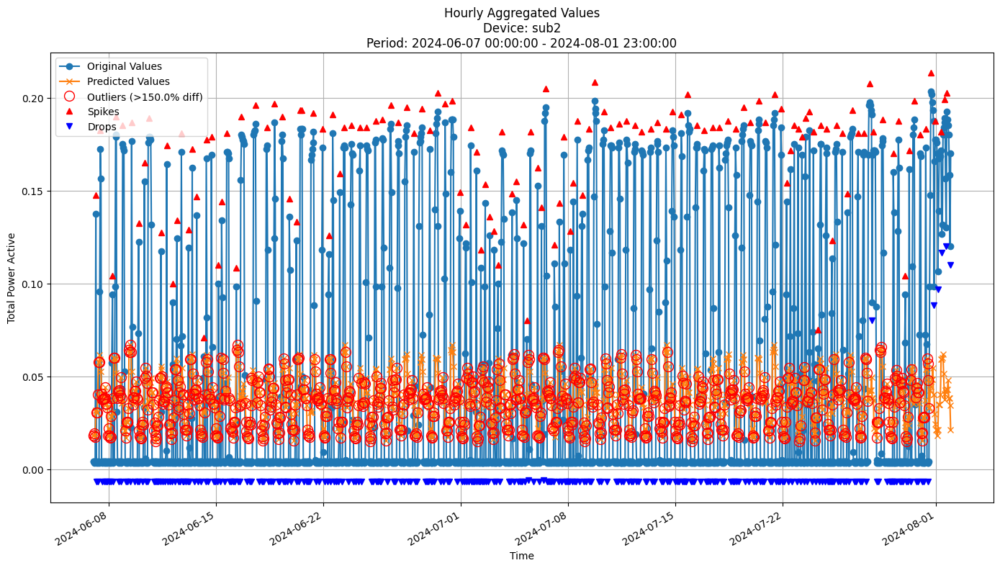


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0679
MAE: 0.0529
MAPE: 546.2887%

Directional Metrics:
Directional Accuracy: 46.9844%
First-Diff Correlation: 0.1891

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


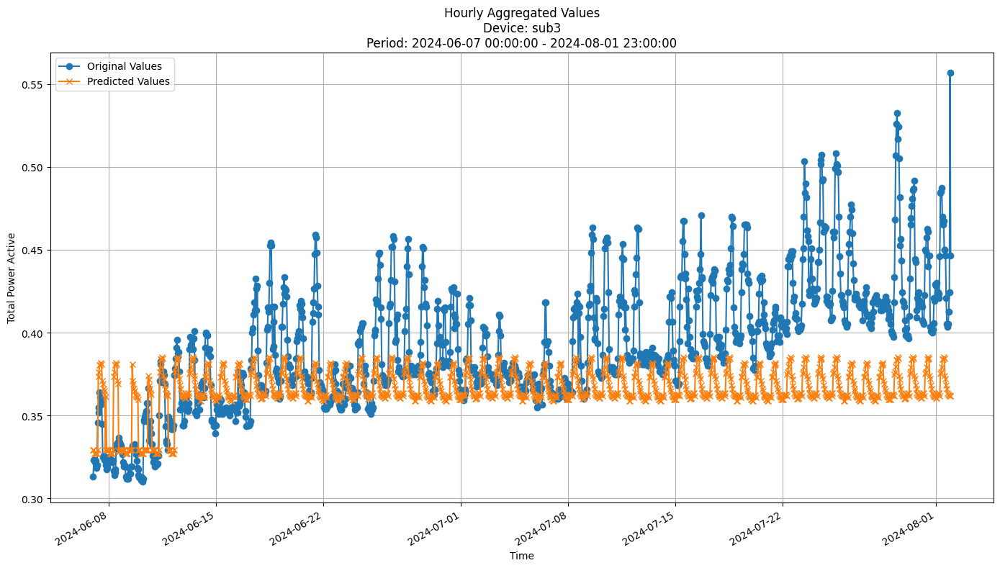


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0415
MAE: 0.0314
MAPE: 7.5573%

Directional Metrics:
Directional Accuracy: 47.3567%
First-Diff Correlation: 0.2369

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


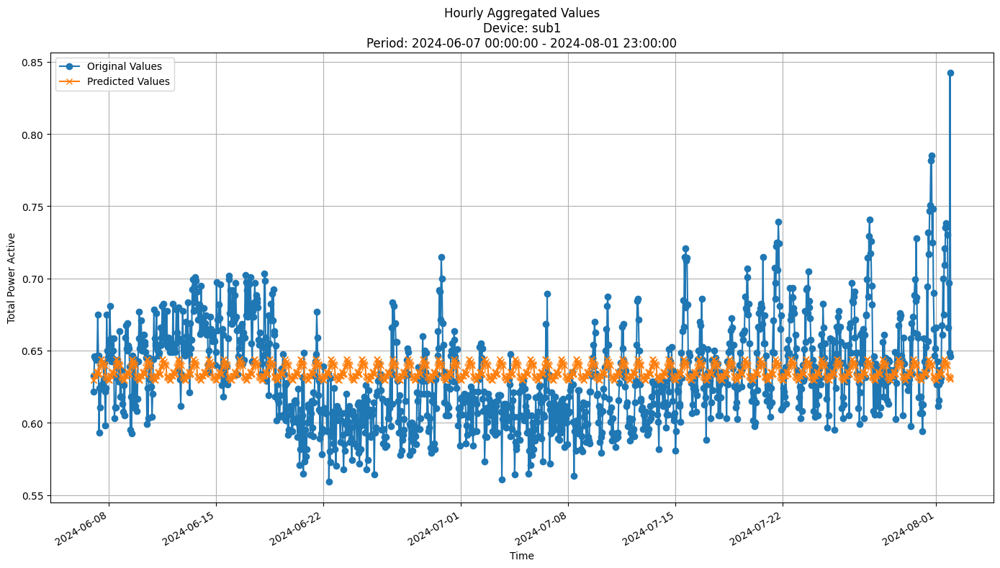


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0330
MAE: 0.0265
MAPE: 4.1691%

Directional Metrics:
Directional Accuracy: 43.6337%
First-Diff Correlation: 0.1113

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [35]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

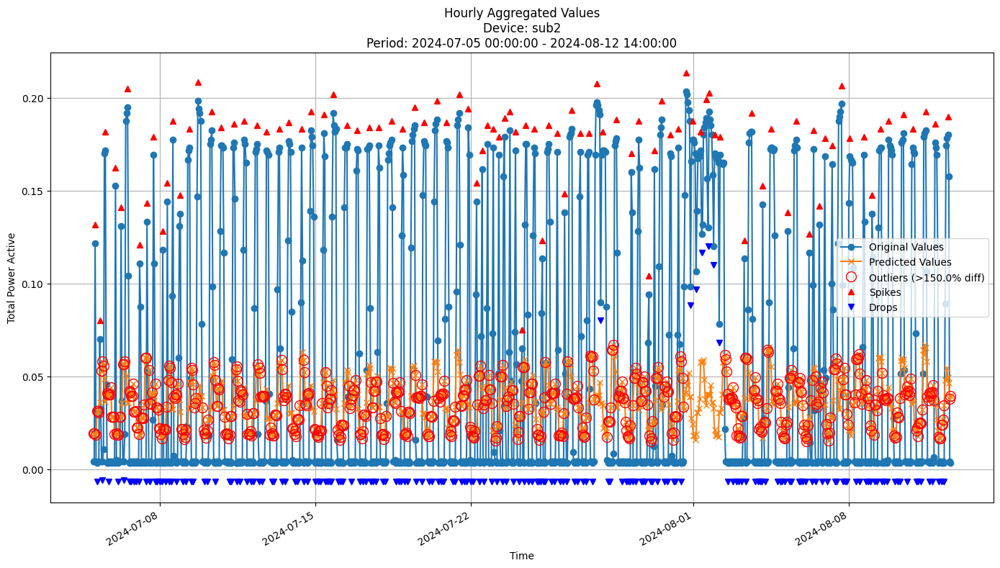


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0750
MAE: 0.0586
MAPE: 512.0065%

Directional Metrics:
Directional Accuracy: 42.4406%
First-Diff Correlation: 0.0222

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


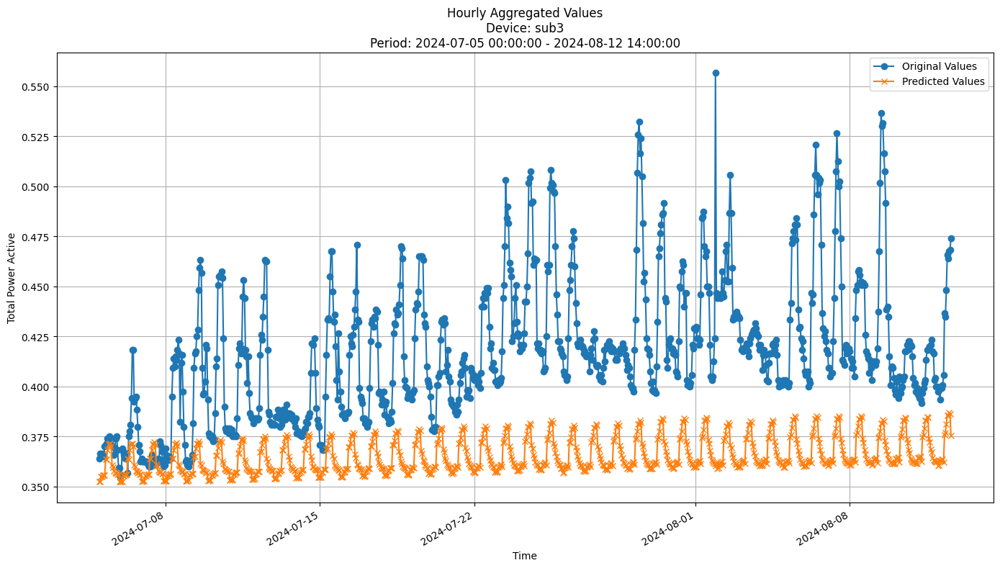


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0595
MAE: 0.0517
MAPE: 11.9276%

Directional Metrics:
Directional Accuracy: 53.9957%
First-Diff Correlation: 0.2865

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


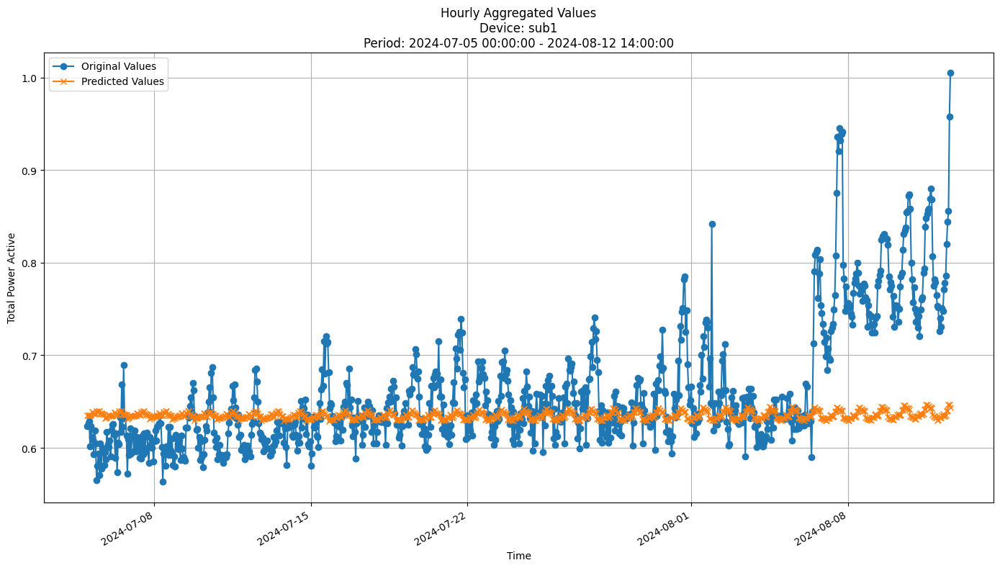


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0701
MAE: 0.0443
MAPE: 6.1418%

Directional Metrics:
Directional Accuracy: 43.0886%
First-Diff Correlation: 0.1483

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [36]:
join_periods = [-2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [37]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = {
    "n_models": 20,
    "aggregation_method": "mean",
    "grace_period": 0,  # by default works for all leaves
    "max_depth": 100,
    "delta": 0.005,  # split confidence
    "tau": 0.01,  # break ties
    "seed": 42,
    "max_feature": 0.7,  # maximum feature ratio for each model
    "eagerness": 200
}

In [38]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0725
	MAE: 0.0571
	MAPE: 495.5000%

Directional Metrics:
	Directional Accuracy: 52.1610%
	First-Diff Correlation: 0.1784

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1148
		Recall: 0.0972
		F1: 0.1053
	Drops:
		Precision: 0.2459
		Recall: 0.1128
		F1: 0.1546

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6393
		Recall: 0.5417
		F1: 0.5865
	Drops:
		Precision: 0.7869
		Recall: 0.3609
		F1: 0.4948
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0712
	MAE: 0.0574
	MAPE: 557.4346%

Directional Metrics:
	Directional Accuracy: 48.0315%
	First-Diff Correlation: 0.0546

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2353
		Recall: 0.1667
		F1: 0.1951
	Drops:
		Precision: 0.3750
		Recall: 0.1132
		F1: 0.1739

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4118
		Recall: 0.2917
		F1: 0.3415
	Drops:
		Precision: 0.9375
		Recall: 0.2830
		F1: 0.4348
--------------------------------------------------
Dai

#### Results

In [39]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0634 ± 0.0026
	MAE: 0.0496 ± 0.0023
	MAPE: 550.3019% ± 12.5903%

	Directional Metrics:
		Directional Accuracy: 53.1095% ± 1.0975%
		First-Diff Correlation: 0.2192 ± 0.0057

	Immediate Detection (delta=0):
		Spike Precision: 0.2093 ± 0.0493
		Spike Recall: 0.1734 ± 0.0574
		Spike F1: 0.1892 ± 0.0547
		Drop Precision: 0.2064 ± 0.0836
		Drop Recall: 0.0788 ± 0.0274
		Drop F1: 0.1140 ± 0.0415

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5872 ± 0.0528
		Spike Recall: 0.4703 ± 0.0066
		Spike F1: 0.5209 ± 0.0169
		Drop Precision: 0.7596 ± 0.0404
		Drop Recall: 0.2973 ± 0.0042
		Drop F1: 0.4269 ± 0.0020
Daily Metrics:
	RMSE: 0.4415 ± 0.1205
	MAE: 0.3341 ± 0.0537
	MAPE: 29.9247% ± 0.1824%

	Directional Metrics:
		Directional Accuracy: 45.8586% ± 1.4141%
		First-Diff Correlation: 0.1391 ± 0.3032

	Immediate Detection (delta=0):
		Sp

#### Training plots

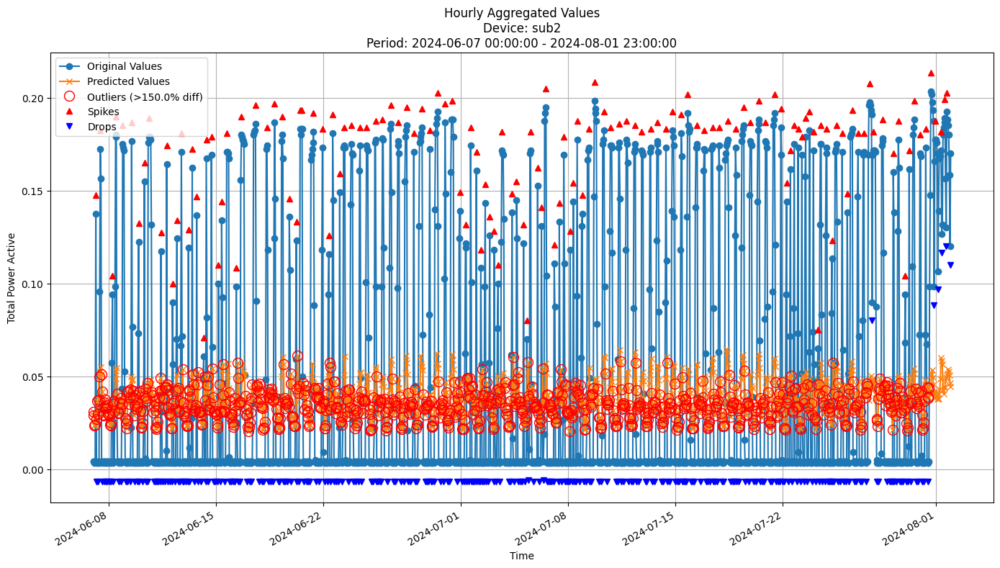


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0660
MAE: 0.0519
MAPE: 537.7116%

Directional Metrics:
Directional Accuracy: 54.2070%
First-Diff Correlation: 0.2249

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


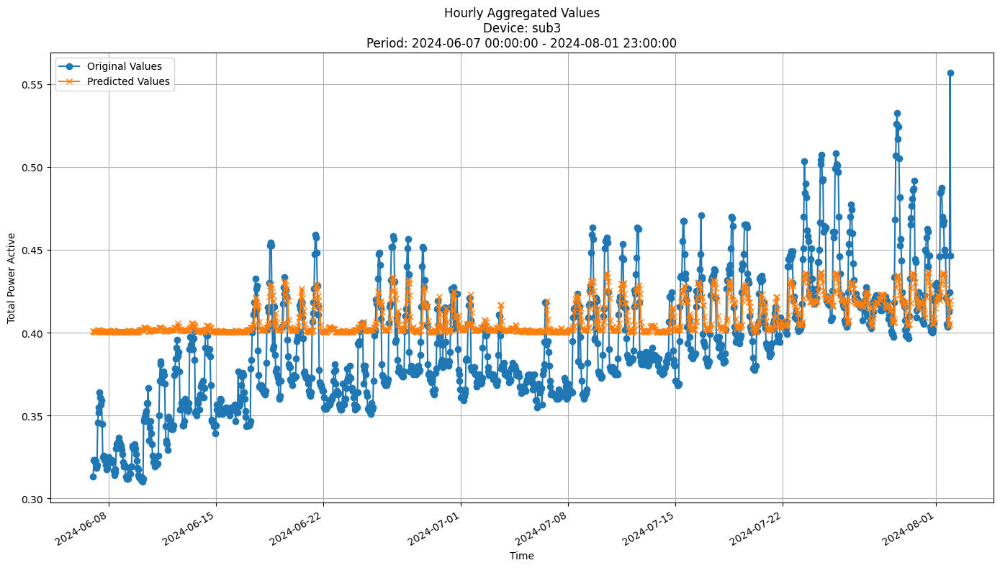


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0347
MAE: 0.0275
MAPE: 7.3926%

Directional Metrics:
Directional Accuracy: 46.6865%
First-Diff Correlation: 0.1917

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


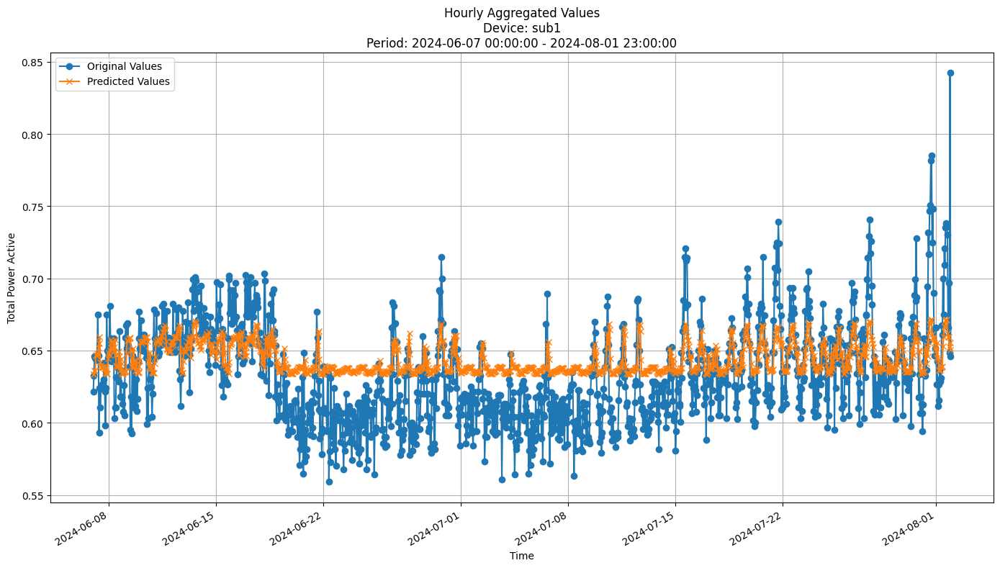


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0294
MAE: 0.0235
MAPE: 3.7707%

Directional Metrics:
Directional Accuracy: 50.2606%
First-Diff Correlation: 0.2065

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [40]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

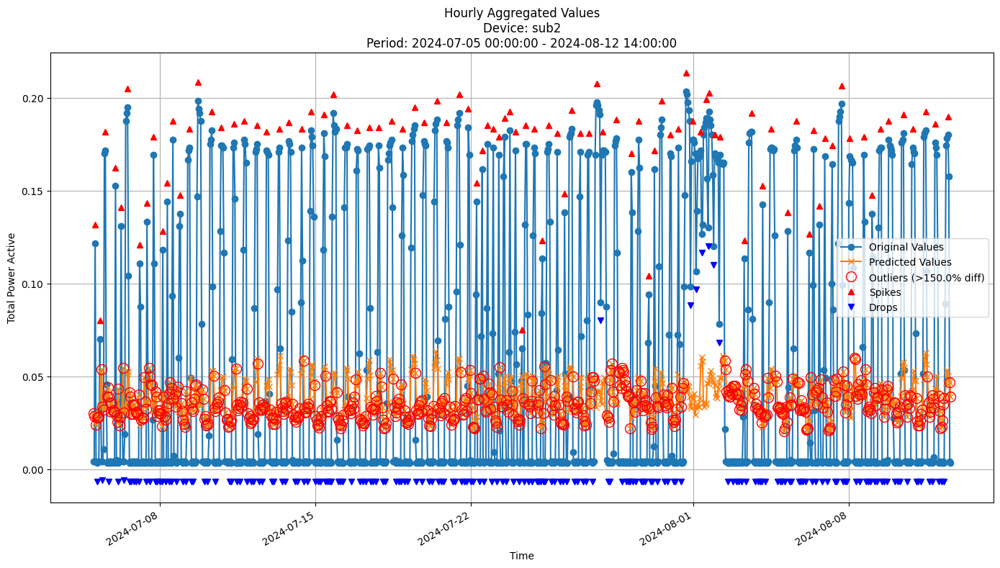


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0721
MAE: 0.0572
MAPE: 512.5370%

Directional Metrics:
Directional Accuracy: 51.0799%
First-Diff Correlation: 0.1512

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


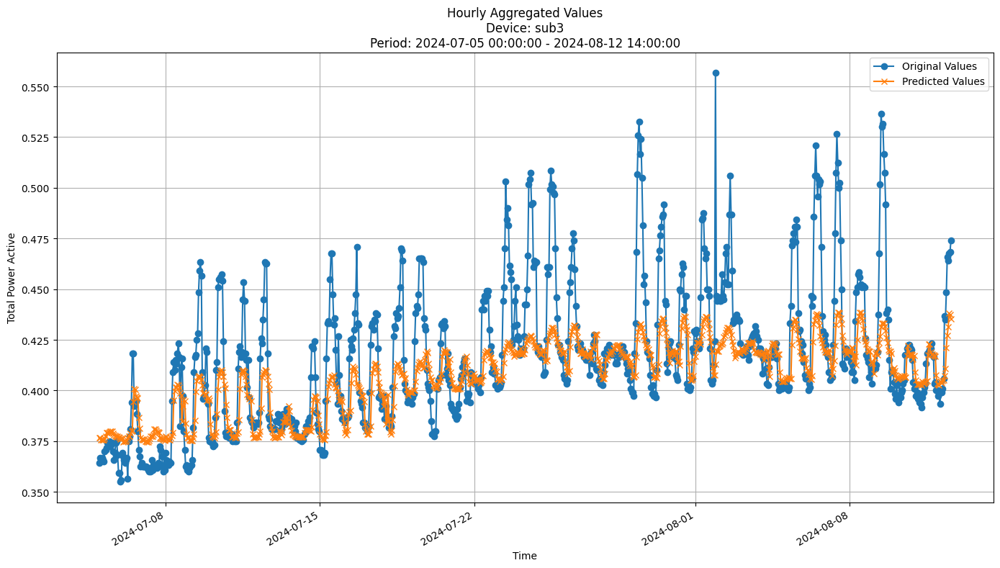


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0255
MAE: 0.0168
MAPE: 3.7946%

Directional Metrics:
Directional Accuracy: 57.9914%
First-Diff Correlation: 0.2225

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


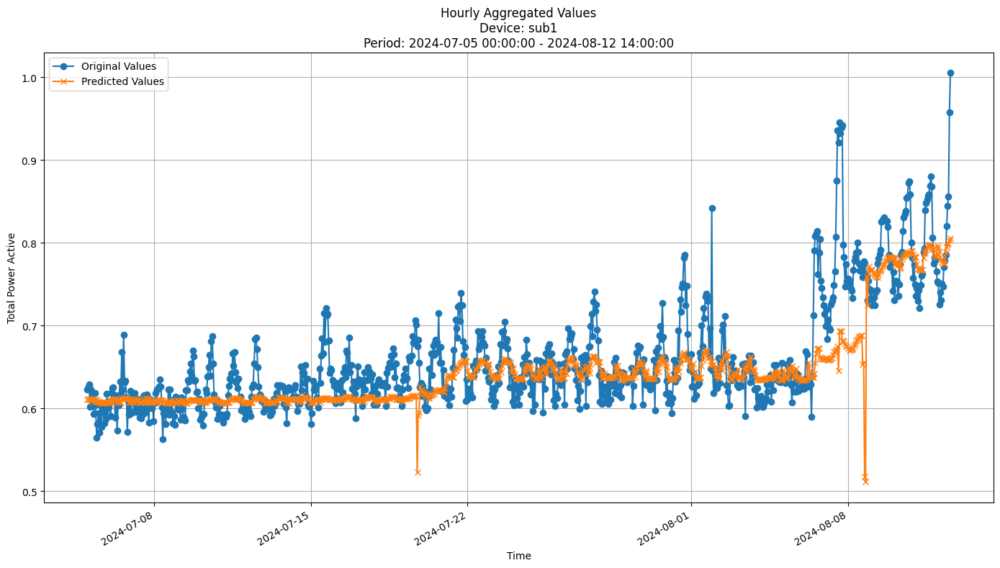


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0451
MAE: 0.0286
MAPE: 4.0706%

Directional Metrics:
Directional Accuracy: 56.2635%
First-Diff Correlation: 0.1014

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [41]:
join_periods = [-2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [42]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

# FastODT params
depth = 10
grace_period = 0
split_confidence_hf = 0.01
option = "hf"
max_features = 1.0
eagerness = 5000
learning_rate = 0.5
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes

incb = IncubationBoost
incb_params = {
    "baseLearner": fastodt.FastODT,
    "length": 100,
    "learning_rate": 0.5,
    "incubationMode": "DEFAULT",
    "verbose": False,
    "baseLearnerOptions": (depth, grace_period, split_confidence_hf, option, max_features, eagerness, grace_period_depth),
}


In [43]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params,
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/2 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-07-04 23:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-07-05 00:00:00+02:00 - 2024-08-01 23:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0732
	MAE: 0.0578
	MAPE: 544.6720%

Directional Metrics:
	Directional Accuracy: 28.9121%
	First-Diff Correlation: 0.0506

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1034
		Recall: 0.0417
		F1: 0.0594
	Drops:
		Precision: 0.6552
		Recall: 0.1429
		F1: 0.2346

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3448
		Recall: 0.1389
		F1: 0.1980
	Drops:
		Precision: 0.9310
		Recall: 0.2030
		F1: 0.3333
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-01 23:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub2 | Period: 2024-08-02 00:00:00+02:00 - 2024-08-12 14:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0730
	MAE: 0.0654
	MAPE: 870.0622%

Directional Metrics:
	Directional Accuracy: 23.6220%
	First-Diff Correlation: 0.0449

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0909
		Recall: 0.0833
		F1: 0.0870
	Drops:
		Precision: 0.0909
		Recall: 0.0377
		F1: 0.0533

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2727
		Recall: 0.2500
		F1: 0.2609
	Drops:
		Precision: 0.4545
		Recall: 0.1887
		F1: 0.2667
--------------------------------------------------
Dai

#### Results

In [44]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: sub2
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0650 ± 0.0022
	MAE: 0.0502 ± 0.0047
	MAPE: 567.2874% ± 98.7902%

	Directional Metrics:
		Directional Accuracy: 28.0440% ± 1.8145%
		First-Diff Correlation: 0.1051 ± 0.0077

	Immediate Detection (delta=0):
		Spike Precision: 0.1972 ± 0.0171
		Spike Recall: 0.1186 ± 0.0263
		Spike F1: 0.1448 ± 0.0158
		Drop Precision: 0.3934 ± 0.0511
		Drop Recall: 0.1137 ± 0.0255
		Drop F1: 0.1726 ± 0.0253

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5153 ± 0.0919
		Spike Recall: 0.3011 ± 0.0395
		Spike F1: 0.3716 ± 0.0060
		Drop Precision: 0.7492 ± 0.0285
		Drop Recall: 0.2237 ± 0.0693
		Drop F1: 0.3372 ± 0.0795
Daily Metrics:
	RMSE: 0.4617 ± 0.0620
	MAE: 0.3323 ± 0.0006
	MAPE: 30.7398% ± 0.6120%

	Directional Metrics:
		Directional Accuracy: 0.0000% ± 0.0000%
		First-Diff Correlation: nan ± nan

	Immediate Detection (delta=0):
		Spike Pre

#### Train plots

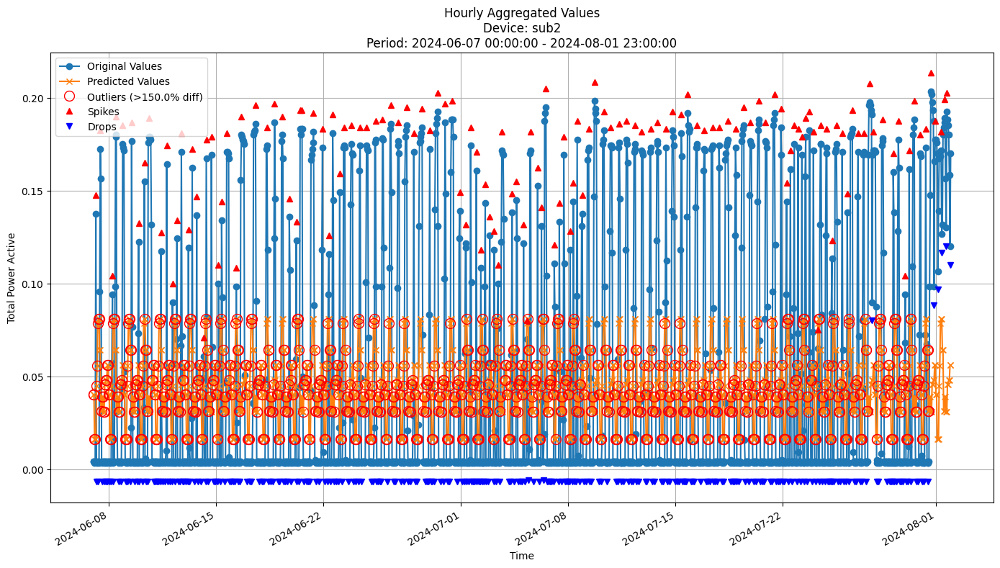


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0672
MAE: 0.0549
MAPE: 666.0776%

Directional Metrics:
Directional Accuracy: 29.8585%
First-Diff Correlation: 0.0974

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


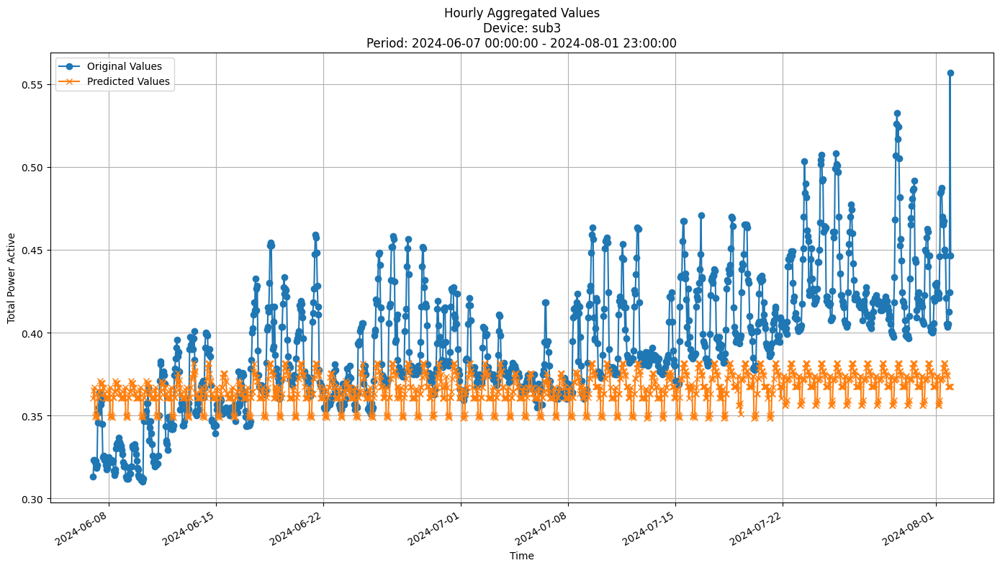


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0421
MAE: 0.0330
MAPE: 8.0351%

Directional Metrics:
Directional Accuracy: 49.7394%
First-Diff Correlation: 0.2489

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


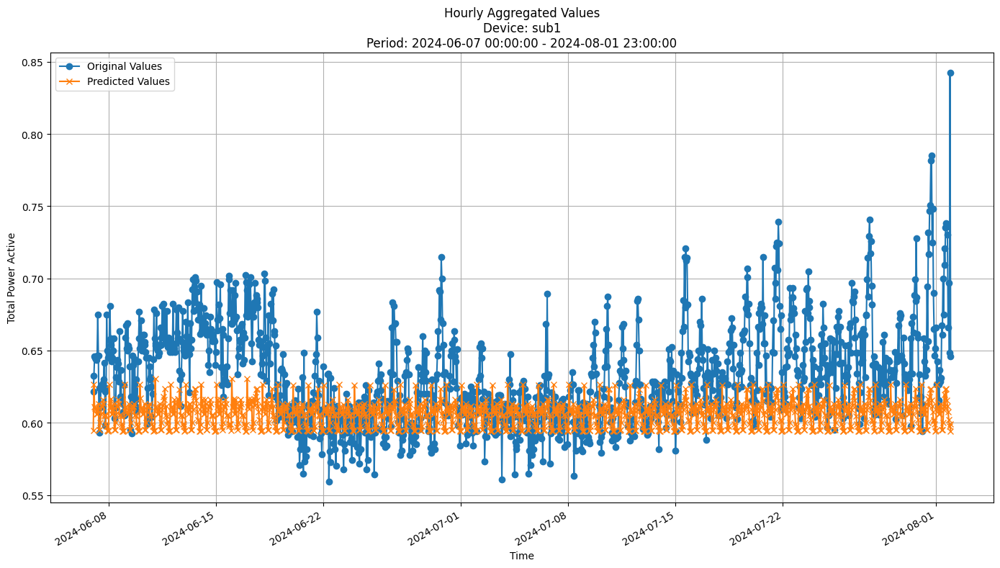


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0425
MAE: 0.0328
MAPE: 5.0041%

Directional Metrics:
Directional Accuracy: 50.3351%
First-Diff Correlation: 0.0486

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [45]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

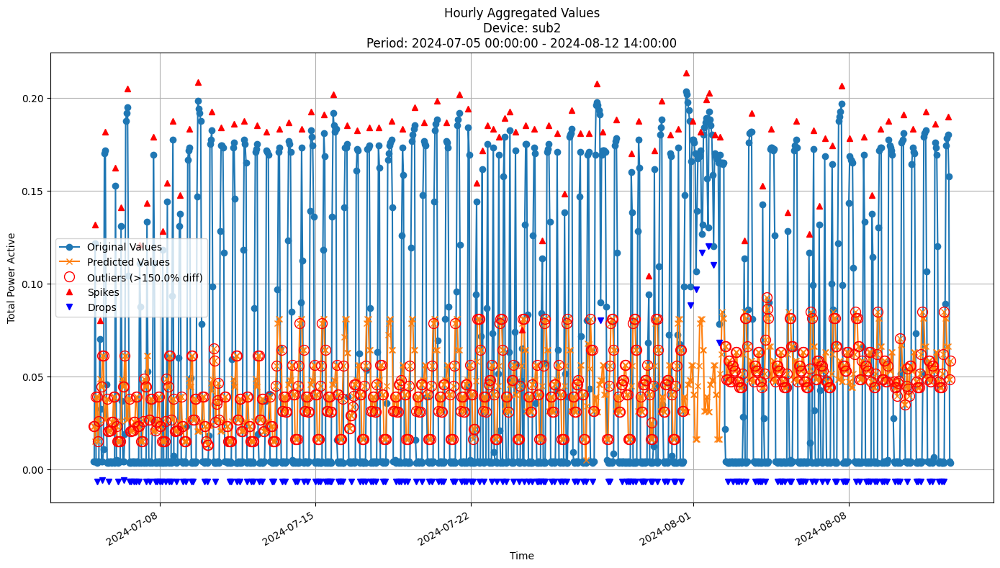


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0731
MAE: 0.0599
MAPE: 634.1806%

Directional Metrics:
Directional Accuracy: 27.5378%
First-Diff Correlation: 0.0492

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


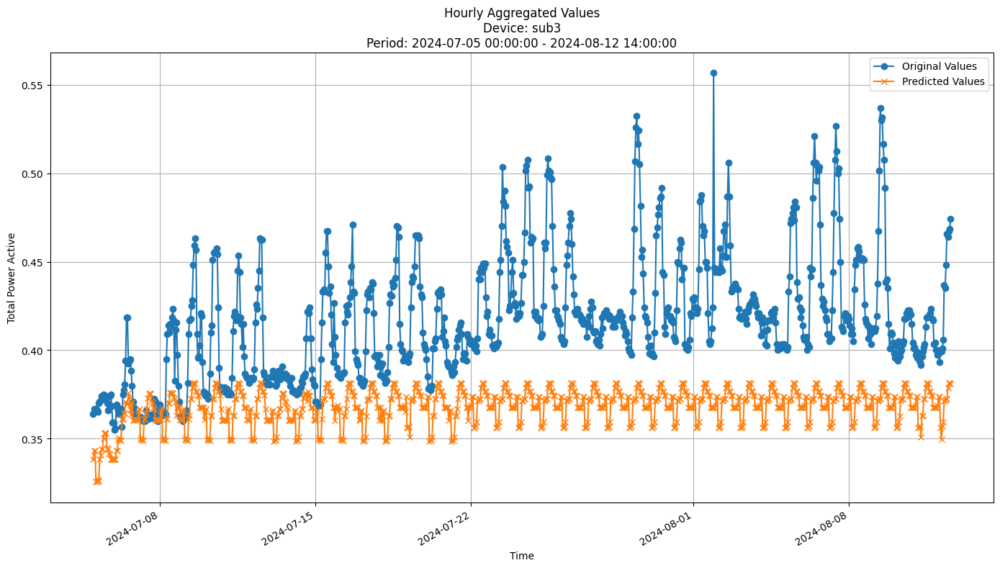


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0570
MAE: 0.0491
MAPE: 11.3211%

Directional Metrics:
Directional Accuracy: 49.0281%
First-Diff Correlation: 0.2189

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


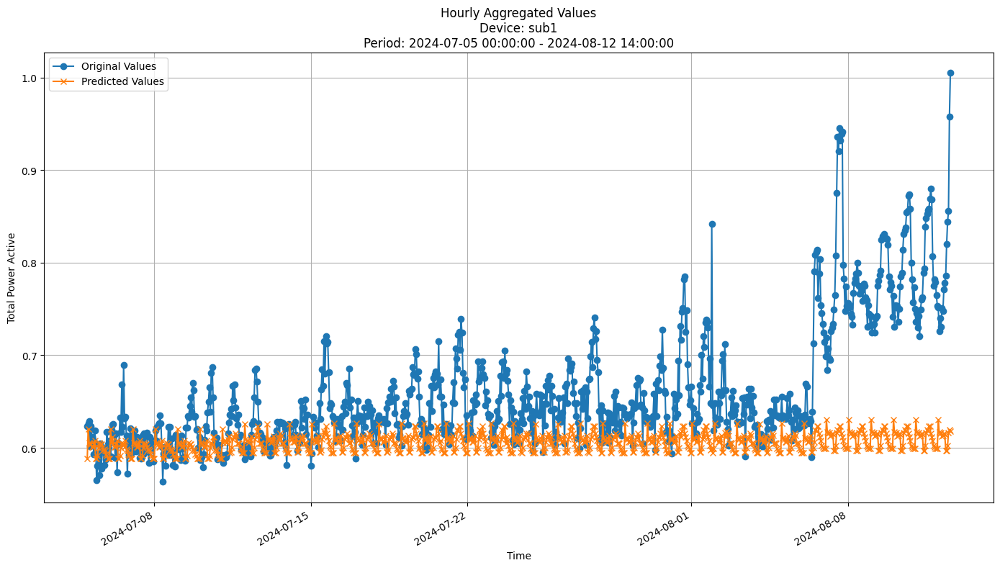


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0837
MAE: 0.0563
MAPE: 7.7908%

Directional Metrics:
Directional Accuracy: 52.3758%
First-Diff Correlation: 0.0971

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [46]:
join_periods = [-2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [47]:
# Initialize the models beforehand to run this cell
models_classes = [baseline, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
models_params = [baseline_params, gbdt_params, rf_params,
                 hoef_params, arf_hf_params, fodt_params, arf_params, incb_params]

model_test_results = {}
for model, params in zip(models_classes, models_params):
    if model in [gbdt, rf]:
        # Batch learning models
        incremental = False
        update_freq = "14D"
        print(f"\n\n\nModel: {model.__name__} - update_freq: {update_freq}")
    else:
        # Incremental learning models
        incremental = True
        update_freq = "1h"
        print(f"\n\n\nModel: {model.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model,
        model_params=params,
        train=train, 
        valid=valid,
        test=test,
        incremental=incremental, 
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=1
    )
    model_test_results[model.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }




Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 14:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub3 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0097
	MAE: 0.0062
	MAPE: 1.5277%

Directional Metrics:
	Directional Accuracy: 45.4321%
	First-Diff Correlation: 0.1988

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]


Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 14:00:00+02:00

Time: 0.41 seconds
Predicting for chunk from 2024-08-12 16:00:00+02:00 to 2024-08-26 16:00:00+02:00

-------------------------

Retraining model on data from 2024-06-07 00:00:00+02:00 to 2024-08-26 16:00:00+02:00

Time: 0.47 seconds
Predicting for chunk from 2024-08-26 17:00:00+02:00 to 2024-08-29 13:00:00+02:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: sub3 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0131
	MAE: 0.0093
	MAPE: 2.2710%

Directional Metrics:
	Directional Accuracy: 55.8025%
	First-Diff Correlation: 0.2667

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1176
		Recall: 0.1176
		F1: 0.1176

Delayed Detection (delta=1 

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

... (7 outputs left out)

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 14:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub3 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0168
	MAE: 0.0137
	MAPE: 3.3764%

Directional Metrics:
	Directional Accuracy: 55.3086%
	First-Diff Correlation: 0.0862

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1000
		Recall: 0.0714
		F1: 0.0833
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3000
		Recall: 0.2143
		F1: 0.2500
	Drops:
		Precision: 0.1000
		Recall: 0.0588
		F1: 0.0741
--------------------------------------------------
Daily

Processing devices for test predictions:   0%|          | 0/3 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-07 00:00:00+02:00 to 2024-08-12 14:00:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: sub3 | Period: 2024-08-12 16:00:00+02:00 - 2024-08-29 13:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0382
	MAE: 0.0330
	MAPE: 7.9714%

Directional Metrics:
	Directional Accuracy: 54.5679%
	First-Diff Correlation: 0.2645

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.4375
		Recall: 0.5000
		F1: 0.4667
	Drops:
		Precision: 0.1176
		Recall: 0.1176
		F1: 0.1176

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4375
		Recall: 0.5000
		F1: 0.4667
	Drops:
		Precision: 0.4118
		Recall: 0.4118
		F1: 0.4118
--------------------------------------------------
Daily

In [48]:
for model in models_classes:
    model_test_results[model.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [49]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [50]:
MODEL_TEST_METRICS = {
    "Baseline": model_test_results[baseline.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

In [51]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f}"# ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [52]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)



============================Hourly Test Results============================


Device: sub1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.028,0.017,1.963,65.432,18.836,0.000,100.000,0.000,100.000
1,GBDT,0.082,0.059,6.432,59.012,13.552,12.500,25.000,17.647,17.647
2,RandomForest,0.068,0.050,5.381,61.975,17.448,26.667,33.333,6.250,12.500
3,HoeffdingTree,0.167,0.145,16.003,43.704,2.260,0.000,6.897,0.000,0.000
4,ARF_Hoeffding,0.153,0.115,12.497,48.148,5.529,0.000,0.000,11.111,11.111
5,FastODT,0.248,0.238,26.616,50.123,13.226,14.286,21.429,6.667,13.333
6,ARF_FastODT,0.076,0.055,5.872,59.753,10.262,14.815,37.037,0.000,7.143
7,IncubationBoost,0.278,0.268,30.016,54.321,-7.901,17.778,31.111,0.000,4.255




Device: sub2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.062,0.034,255.408,45.185,12.933,0.000,100.000,0.000,100.000
1,GBDT,0.067,0.052,564.509,50.123,14.851,17.284,44.444,16.364,49.091
2,RandomForest,0.063,0.052,588.162,53.580,20.130,12.048,53.012,28.571,55.357
3,HoeffdingTree,0.073,0.062,707.711,41.975,11.820,0.000,17.778,13.333,45.000
4,ARF_Hoeffding,0.073,0.062,672.045,47.901,2.290,7.317,36.585,12.613,37.838
5,FastODT,0.079,0.063,515.287,42.222,-3.571,3.125,9.375,10.638,19.149
6,ARF_FastODT,0.076,0.062,505.016,51.605,5.085,5.405,32.432,23.077,42.308
7,IncubationBoost,0.076,0.068,779.559,29.383,-1.722,15.190,35.443,20.370,48.148




Device: sub3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.010,0.006,1.528,45.432,19.885,0.000,100.000,0.000,100.000
1,GBDT,0.013,0.009,2.271,55.802,26.672,0.000,26.667,11.765,29.412
2,RandomForest,0.012,0.009,2.280,56.543,24.651,7.143,35.714,25.806,45.161
3,HoeffdingTree,0.019,0.016,3.899,46.914,27.069,19.355,19.355,0.000,28.571
4,ARF_Hoeffding,0.015,0.012,2.895,51.605,48.867,0.000,42.857,0.000,12.500
5,FastODT,0.039,0.034,8.214,48.889,40.033,0.000,66.667,5.882,11.765
6,ARF_FastODT,0.017,0.014,3.376,55.309,8.618,8.333,25.000,0.000,7.407
7,IncubationBoost,0.038,0.033,7.971,54.568,26.455,46.667,46.667,11.765,41.176


## Validation results

In [53]:
MODEL_VALID_METRICS = {
    "Baseline": baseline_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)



============================Hourly Validation Results============================


Device: sub1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.025,0.018,2.626,41.266,-25.975,0.000,99.275,0.000,100.000
1,GBDT,0.045,0.031,4.151,52.273,11.256,5.063,10.127,1.282,5.128
2,RandomForest,0.047,0.033,4.449,54.140,15.698,8.475,10.169,6.897,8.621
3,HoeffdingTree,0.066,0.051,6.907,46.552,0.657,1.389,5.556,2.857,8.571
4,ARF_Hoeffding,0.068,0.051,6.838,52.437,7.482,5.479,15.839,1.408,5.634
5,FastODT,0.078,0.059,7.879,43.848,17.564,1.613,8.065,1.639,6.557
6,ARF_FastODT,0.050,0.034,4.606,56.806,12.842,8.333,68.750,0.000,2.128
7,IncubationBoost,0.093,0.074,9.897,53.145,11.717,9.890,24.326,8.989,14.607




Device: sub2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.058,0.031,243.771,41.167,10.417,0.000,100.000,0.000,99.811
1,GBDT,0.088,0.073,1280.760,48.415,9.386,10.615,42.411,16.352,41.113
2,RandomForest,0.073,0.062,991.706,50.884,19.968,16.770,41.822,16.540,42.045
3,HoeffdingTree,0.074,0.060,679.446,44.748,3.312,8.527,37.209,18.670,41.550
4,ARF_Hoeffding,0.070,0.057,613.666,47.526,7.462,11.455,38.894,8.865,31.423
5,FastODT,0.075,0.059,523.024,42.545,0.968,8.685,24.187,9.656,27.407
6,ARF_FastODT,0.072,0.057,526.467,50.096,11.654,15.019,46.396,16.428,46.481
7,IncubationBoost,0.073,0.062,707.367,26.267,4.776,7.318,22.944,14.395,30.000




Device: sub3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.012,0.007,1.650,50.953,24.979,0.000,98.936,0.000,100.000
1,GBDT,0.024,0.018,4.167,52.645,15.399,10.819,43.275,9.091,22.727
2,RandomForest,0.021,0.016,3.572,55.099,22.680,11.014,34.928,10.598,27.446
3,HoeffdingTree,0.037,0.030,6.845,50.452,20.795,8.711,19.056,0.000,6.897
4,ARF_Hoeffding,0.034,0.028,6.411,58.275,41.421,10.694,26.250,13.333,23.660
5,FastODT,0.062,0.055,12.559,54.433,28.633,5.769,28.959,7.805,9.729
6,ARF_FastODT,0.026,0.017,3.785,56.211,25.804,2.941,34.706,15.074,18.015
7,IncubationBoost,0.060,0.052,12.020,47.409,19.413,11.538,31.731,24.214,33.648


### By-period validation results

In [54]:
MODEL_VALID_PERIOD_METRICS = {
    "Baseline": baseline_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)

In [55]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,31.744,54.545,53.949,46.647,52.906,42.027,55.738,51.565,48.640125
Period 2,50.787,50.000,54.331,46.457,51.969,45.669,57.874,54.724,51.476375



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,19.043,-4.545,0.382,-0.190,-0.937,3.642,2.136,3.159,2.836



Device: sub2 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,42.176,50.373,52.161,45.007,49.776,42.176,52.161,28.912,45.34275
Period 2,40.157,46.457,49.606,44.488,45.276,42.913,48.031,23.622,42.56875


... (2 outputs left out)


Device: sub3 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,51.118,55.291,59.016,49.329,59.463,53.353,60.060,51.118,54.843500
Period 2,50.787,50.000,51.181,51.575,57.087,55.512,52.362,43.701,51.525625



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.331,-5.291,-7.835,2.246,-2.376,2.159,-7.698,-7.417,-3.318


#### MAPE (lower is better)

In [56]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,2.894,2.870,2.722,3.671,3.248,4.017,3.416,5.215,3.506625
Period 2,2.358,5.432,6.176,10.143,10.427,11.742,5.795,14.579,8.331500



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.536,2.562,3.454,6.472,7.179,7.725,2.379,9.364,4.825



Device: sub2 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,258.949,478.091,444.605,574.318,492.827,498.532,495.500,544.672,473.43675
Period 2,228.593,2083.429,1538.807,784.575,734.505,547.516,557.435,870.062,918.11525


... (2 outputs left out)


Device: sub3 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,1.704,3.770,3.479,7.162,6.290,11.155,3.806,10.467,5.979125
Period 2,1.595,4.564,3.665,6.527,6.532,13.964,3.763,13.573,6.772875



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.109,0.794,0.186,-0.635,0.242,2.809,-0.043,3.106,0.794


#### RMSE (lower is better)

In [57]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: sub1 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.025,0.025,0.025,0.031,0.029,0.034,0.031,0.045,0.030625
Period 2,0.024,0.065,0.069,0.102,0.106,0.121,0.070,0.141,0.087250



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.001,0.040,0.044,0.071,0.077,0.087,0.039,0.096,0.057



Device: sub2 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.060,0.066,0.064,0.073,0.069,0.075,0.072,0.073,0.069000
Period 2,0.056,0.110,0.083,0.075,0.071,0.074,0.071,0.073,0.076625


... (2 outputs left out)


Device: sub3 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.013,0.023,0.022,0.037,0.033,0.056,0.025,0.053,0.03275
Period 2,0.012,0.025,0.020,0.036,0.034,0.068,0.028,0.067,0.03625



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,-0.001,0.002,-0.002,-0.001,0.001,0.012,0.003,0.014,0.004
